In [11]:
def calculate_event(close, election_date):
    returns = np.log(close / close.shift(1)).dropna()

    before = returns[returns.index < election_date]
    after = returns[returns.index > election_date]

    result = {"election_date": election_date}

    for label, window, required_n in [
        ("pre20", before.tail(20), 20),
        ("post5", after.head(5), 5),
        ("post20", after.head(20), 20),
        ("post60", after.head(60), 60),
    ]:
        if len(window) != required_n:
            result[f"{label}_return"] = np.nan
            result[f"{label}_rv"] = np.nan
            continue

        result[f"{label}_return"] = np.expm1(window.sum()) * 100
        result[f"{label}_rv"] = np.sqrt((window ** 2).sum()) * 100

    return result


records = []

for asset, close in prices.items():
    for _, election in elections.iterrows():
        metrics = calculate_event(close, election["election_date"])

        records.append({
            "asset": asset,
            "year": int(election["election_year"]),
            **metrics,
        })

event_panel = pd.DataFrame(records)

# Check coverage before interpreting anything.
coverage = (
    event_panel.groupby("asset")
    .agg(
        elections=("year", "nunique"),
        valid_pre20=("pre20_return", "count"),
        valid_post5=("post5_return", "count"),
        valid_post20=("post20_return", "count"),
        valid_post60=("post60_return", "count"),
    )
)

display(coverage)

# Print the SPX results as a consistency check against the earlier notebook.
display(
    event_panel.loc[
        event_panel["asset"].eq("SPX"),
        ["year", "pre20_return", "post5_return",
         "post20_return", "post60_return"]
    ].round(3)
)

event_panel.to_csv(
    PROCESSED / "conditional_probability_event_panel.csv",
    index=False
)

,elections,valid_pre20,valid_post5,valid_post20,valid_post60
asset,,,,,
DOW,16,16,16,16,16
NASDAQ,16,13,16,16,16
QQQ,16,6,15,15,15
SPX,16,16,16,16,16
SPY,16,6,16,16,16


,year,pre20_return,post5_return,post20_return,post60_return
0,1962,2.243,1.902,6.924,13.642
1,1966,8.319,1.189,1.226,8.213
2,1970,-3.423,0.677,5.058,13.845
3,1974,12.517,-1.917,-10.252,2.490
4,1978,-8.987,-1.449,3.879,6.020
5,1982,11.490,4.022,0.756,3.091
6,1986,4.694,0.357,3.107,11.324
7,1990,0.354,1.941,5.873,10.086
8,1994,0.876,-0.133,-3.097,3.337
9,1998,12.446,1.568,5.438,14.601


In [14]:
# CELL 1 — Verify actual event-level coverage

for asset in ["SPX", "DOW", "NASDAQ", "SPY", "QQQ"]:
    print(f"\n{asset}")
    print("Price range:", prices[asset].index.min(), "to", prices[asset].index.max())
    print("Number of prices:", len(prices[asset]))

    subset = event_panel[event_panel["asset"] == asset].copy()

    cols = [
        c for c in [
            "year", "pre20_return", "post5_return",
            "post20_return", "post60_return"
        ]
        if c in subset.columns
    ]

    print(subset[cols].to_string(index=False))

    print("\nNon-null counts:")
    print(subset[cols].notna().sum())


SPX
Price range: 1959-08-25 00:00:00 to 2026-10-27 00:00:00
Number of prices: 16938
 year  pre20_return  post5_return  post20_return  post60_return
 1962      2.242856      1.902315       6.923738      13.641817
 1966      8.318803      1.189148       1.226307       8.212558
 1970     -3.423151      0.676799       5.058183      13.844688
 1974     12.517329     -1.917192     -10.251627       2.489684
 1978     -8.987470     -1.449121       3.878530       6.020247
 1982     11.489712      4.022111       0.756419       3.091134
 1986      4.693756      0.357433       3.107230      11.324127
 1990      0.354090      1.941467       5.872537      10.086002
 1994      0.875741     -0.133147      -3.096746       3.337270
 1998     12.446387      1.568183       5.438227      14.600663
 2002     15.672117     -3.544898       0.232685      -6.017042
 2006      2.155983      0.750629       2.173787       4.712042
 2010      4.164358      1.661402       1.047278       6.934658
 2014      2.696939

In [19]:
DATA_DIR = Path("data")
PROCESSED_DIR = DATA_DIR / "processed"

market = pd.read_csv(
    PROCESSED_DIR / "market_daily.csv",
    parse_dates=["date"]
)

elections = pd.read_csv(
    PROCESSED_DIR / "election_events.csv",
    parse_dates=["election_date"]
)

market = (
    market.sort_values("date")
          .drop_duplicates(subset="date", keep="last")
)

elections = elections.sort_values("election_date")

close_columns = {
    "SPX": "spx_close",
    "DJI": "dji_close",
    "NASDAQ": "nasdaq_close",
    "SPY": "spy_close",
    "QQQ": "qqq_close",
}

prices = {}

for asset, column in close_columns.items():
    close = pd.to_numeric(market[column], errors="coerce")

    close.index = pd.DatetimeIndex(market["date"]).normalize()
    close = close.dropna().sort_index()

    # Retain only valid positive prices.
    close = close[close > 0]

    # Never silently treat duplicate dates as separate observations.
    close = close[~close.index.duplicated(keep="last")]

    prices[asset] = close.astype(float)

# Audit the dataset before calculating any returns.
audit = pd.DataFrame([
    {
        "asset": asset,
        "observations": len(close),
        "first_date": close.index.min().date() if len(close) else None,
        "last_date": close.index.max().date() if len(close) else None,
        "duplicate_dates": int(close.index.has_duplicates),
        "missing_values": int(close.isna().sum()),
    }
    for asset, close in prices.items()
])

display(audit)

,asset,observations,first_date,last_date,duplicate_dates,missing_values
0,SPX,16938,1959-08-25,2026-10-27,0,0
1,DJI,19447,1949-07-12,2026-10-27,0,0
2,NASDAQ,14049,1971-02-05,2026-10-27,0,0
3,SPY,6737,2000-01-03,2026-10-16,0,0
4,QQQ,4853,2000-01-03,2019-04-18,0,0


Data viz

In [21]:

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from IPython.display import display

DATA_DIR = Path("data")
PROCESSED_DIR = DATA_DIR / "processed"
OUTPUT_DIR = PROCESSED_DIR / "midterm_final_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

market = pd.read_csv(
    PROCESSED_DIR / "market_daily.csv",
    parse_dates=["date"]
)

elections = pd.read_csv(
    PROCESSED_DIR / "election_events.csv",
    parse_dates=["election_date"]
)

market["date"] = pd.to_datetime(market["date"]).dt.normalize()
elections["election_date"] = pd.to_datetime(
    elections["election_date"]
).dt.normalize()

market = (
    market.sort_values("date")
          .drop_duplicates(subset="date", keep="last")
)

elections = (
    elections.sort_values("election_date")
             .drop_duplicates(subset="election_date", keep="first")
             .reset_index(drop=True)
)

close_columns = {
    "SPX": "spx_close",
    "DJI": "dji_close",
    "NASDAQ": "nasdaq_close",
    "SPY": "spy_close",
    "QQQ": "qqq_close",
}

prices = {}

for asset, column in close_columns.items():
    close = pd.to_numeric(market[column], errors="coerce")
    close.index = pd.DatetimeIndex(market["date"])
    close = close.dropna().sort_index()
    close = close[~close.index.duplicated(keep="last")]
    prices[asset] = close[close > 0].astype(float)

# Confirm the source data's actual coverage.
audit = pd.DataFrame([
    {
        "asset": asset,
        "observations": len(close),
        "first_date": close.index.min().date() if len(close) else None,
        "last_date": close.index.max().date() if len(close) else None,
        "duplicate_dates": int(close.index.has_duplicates),
        "missing_values": int(close.isna().sum()),
    }
    for asset, close in prices.items()
])

display(audit)

# The study should contain historical midterm events only.
if "event_type" in elections.columns:
    print("Event types in election file:")
    display(elections["event_type"].value_counts(dropna=False))

    midterm_mask = (
        elections["event_type"].astype(str).str.contains(
            "midterm", case=False, na=False
        )
    )

    if midterm_mask.any():
        elections = elections.loc[midterm_mask].copy()
    else:
        warnings.warn(
            "No event_type value explicitly contains 'midterm'. "
            "Check election_events.csv before proceeding."
        )

elections = elections.sort_values("election_date").reset_index(drop=True)

print(f"Historical midterm events included: {len(elections)}")
print(
    "Latest completed election event:",
    elections["election_date"].max().date()
)

assert len(elections) > 0
assert prices["SPX"].index.is_monotonic_increasing
assert prices["DJI"].index.is_monotonic_increasing
assert not prices["SPX"].index.has_duplicates
assert not prices["DJI"].index.has_duplicates

# These are source-coverage checks, not assumptions about event outcomes.
for asset, close in prices.items():
    assert (close > 0).all(), f"{asset} has non-positive prices."

print("Data loaded and basic validation passed.")


,asset,observations,first_date,last_date,duplicate_dates,missing_values
0,SPX,16938,1959-08-25,2026-10-27,0,0
1,DJI,19447,1949-07-12,2026-10-27,0,0
2,NASDAQ,14049,1971-02-05,2026-10-27,0,0
3,SPY,6737,2000-01-03,2026-10-16,0,0
4,QQQ,4853,2000-01-03,2019-04-18,0,0


Event types in election file:


event_type
Midterm    16
Name: count, dtype: int64

Historical midterm events included: 16
Latest completed election event: 2022-11-08
Data loaded and basic validation passed.


In [22]:

HORIZONS = [5, 20, 60]

def compounded_return_pct(log_returns):
    """Convert a series of log returns into a compounded percentage return."""
    if len(log_returns) == 0:
        return np.nan
    return np.expm1(log_returns.sum()) * 100


def calculate_event(close, election_date):
    close = close.dropna().sort_index()
    election_date = pd.Timestamp(election_date).normalize()

    result = {
        "pre20_return": np.nan,
        "post5_return": np.nan,
        "post20_return": np.nan,
        "post60_return": np.nan,
        "pre20_rv": np.nan,
        "post20_rv": np.nan,
    }

    if close.empty:
        return result

    # Do not estimate an event outcome for an asset that did not yet exist.
    if election_date < close.index.min():
        return result

    log_returns = np.log(close / close.shift(1)).dropna()

    # Only returns whose ending close is strictly before election date.
    pre = log_returns.loc[log_returns.index < election_date]

    # Only returns whose ending close is strictly after election date.
    post = log_returns.loc[log_returns.index > election_date]

    if len(pre) >= 20:
        window = pre.iloc[-20:]
        result["pre20_return"] = compounded_return_pct(window)
        result["pre20_rv"] = np.sqrt(np.square(window).sum()) * 100

    for horizon in HORIZONS:
        if len(post) >= horizon:
            window = post.iloc[:horizon]
            result[f"post{horizon}_return"] = compounded_return_pct(window)

            if horizon == 20:
                result["post20_rv"] = (
                    np.sqrt(np.square(window).sum()) * 100
                )

    return result


event_rows = []

for _, event in elections.iterrows():
    for asset, close in prices.items():
        metrics = calculate_event(close, event["election_date"])

        event_rows.append({
            "year": int(event["election_date"].year),
            "election_date": event["election_date"],
            "asset": asset,
            **metrics,
        })

event_panel = pd.DataFrame(event_rows)

# One row per election and asset.
assert not event_panel.duplicated(["year", "asset"]).any()

# Crucial validation: no pre-inception ETF event may have a return.
for asset in ["SPY", "QQQ"]:
    inception = prices[asset].index.min()
    before_inception = event_panel[
        (event_panel["asset"] == asset)
        & (event_panel["election_date"] < inception)
    ]

    return_columns = [
        "pre20_return",
        "post5_return",
        "post20_return",
        "post60_return",
    ]

    assert before_inception[return_columns].isna().all().all()

coverage = (
    event_panel.groupby("asset")
    .agg(
        elections=("year", "nunique"),
        valid_pre20=("pre20_return", "count"),
        valid_post5=("post5_return", "count"),
        valid_post20=("post20_return", "count"),
        valid_post60=("post60_return", "count"),
    )
    .reset_index()
)

display(coverage)

# Save the full event-level calculation for reproducibility.
event_panel.to_csv(
    OUTPUT_DIR / "event_level_returns.csv",
    index=False
)

print("Event windows calculated and saved.")


,asset,elections,valid_pre20,valid_post5,valid_post20,valid_post60
0,DJI,16,16,16,16,16
1,NASDAQ,16,13,13,13,13
2,QQQ,16,6,5,5,5
3,SPX,16,16,16,16,16
4,SPY,16,6,6,6,6


Event windows calculated and saved.


In [23]:

def wilson_interval(successes, n, z=1.959963984540054):
    if n == 0:
        return np.nan, np.nan

    p = successes / n
    denominator = 1 + z**2 / n

    center = (
        p + z**2 / (2 * n)
    ) / denominator

    half_width = (
        z * np.sqrt(
            p * (1 - p) / n
            + z**2 / (4 * n**2)
        ) / denominator
    )

    return center - half_width, center + half_width


probability_rows = []
summary_rows = []

for asset in prices:
    asset_events = event_panel[event_panel["asset"] == asset]

    for horizon in HORIZONS:
        column = f"post{horizon}_return"
        returns = asset_events[column].dropna()

        n = len(returns)
        positive = int((returns > 0).sum())
        negative = int((returns < 0).sum())
        flat = int((returns == 0).sum())

        low, high = wilson_interval(positive, n)

        probability_rows.append({
            "asset": asset,
            "horizon_sessions": horizon,
            "valid_events": n,
            "positive_events": positive,
            "negative_events": negative,
            "flat_events": flat,
            "positive_probability": positive / n if n else np.nan,
            "ci95_low": low,
            "ci95_high": high,
        })

        summary_rows.append({
            "asset": asset,
            "horizon_sessions": horizon,
            "valid_events": n,
            "mean_return_pct": returns.mean() if n else np.nan,
            "median_return_pct": returns.median() if n else np.nan,
            "std_return_pct": returns.std(ddof=1) if n > 1 else np.nan,
            "best_return_pct": returns.max() if n else np.nan,
            "worst_return_pct": returns.min() if n else np.nan,
            "positive_events": positive,
            "positive_probability": positive / n if n else np.nan,
        })

probability_table = pd.DataFrame(probability_rows)
return_summary = pd.DataFrame(summary_rows)

# Readable display versions; retain full precision in saved CSV files.
display_probability = probability_table.copy()

for column in ["positive_probability", "ci95_low", "ci95_high"]:
    display_probability[column] = (
        display_probability[column] * 100
    ).round(1)

display(display_probability)

display(
    return_summary.round(3)
)

probability_table.to_csv(
    OUTPUT_DIR / "positive_return_probabilities.csv",
    index=False
)

return_summary.to_csv(
    OUTPUT_DIR / "return_summary_statistics.csv",
    index=False
)

print("Probability and return-summary tables saved.")


,asset,horizon_sessions,valid_events,positive_events,negative_events,flat_events,positive_probability,ci95_low,ci95_high
0,SPX,5,16,11,5,0,68.8,44.4,85.8
1,SPX,20,16,13,3,0,81.2,57.0,93.4
2,SPX,60,16,14,2,0,87.5,64.0,96.5
3,DJI,5,16,11,5,0,68.8,44.4,85.8
4,DJI,20,16,13,3,0,81.2,57.0,93.4
5,DJI,60,16,13,3,0,81.2,57.0,93.4
6,NASDAQ,5,13,8,5,0,61.5,35.5,82.3
7,NASDAQ,20,13,10,3,0,76.9,49.7,91.8
8,NASDAQ,60,13,12,1,0,92.3,66.7,98.6
9,SPY,5,6,4,2,0,66.7,30.0,90.3


,asset,horizon_sessions,valid_events,mean_return_pct,median_return_pct,std_return_pct,best_return_pct,worst_return_pct,positive_events,positive_probability
0,SPX,5,16,0.716,0.970,2.051,4.275,-3.545,11,0.688
1,SPX,20,16,1.629,2.469,4.198,6.924,-10.252,13,0.812
2,SPX,60,16,6.216,6.477,5.744,14.601,-6.017,14,0.875
3,DJI,5,16,0.515,1.258,1.884,3.735,-3.368,11,0.688
4,DJI,20,16,1.154,1.286,4.189,7.127,-11.280,13,0.812
5,DJI,60,16,5.178,4.292,5.403,14.035,-6.550,13,0.812
6,NASDAQ,5,13,1.243,0.799,3.207,6.991,-3.683,8,0.615
7,NASDAQ,20,13,2.371,2.945,5.508,11.551,-8.456,10,0.769
8,NASDAQ,60,13,9.233,6.054,11.765,40.352,-5.523,12,0.923
9,SPY,5,6,0.643,1.169,2.684,4.335,-3.501,4,0.667


Probability and return-summary tables saved.


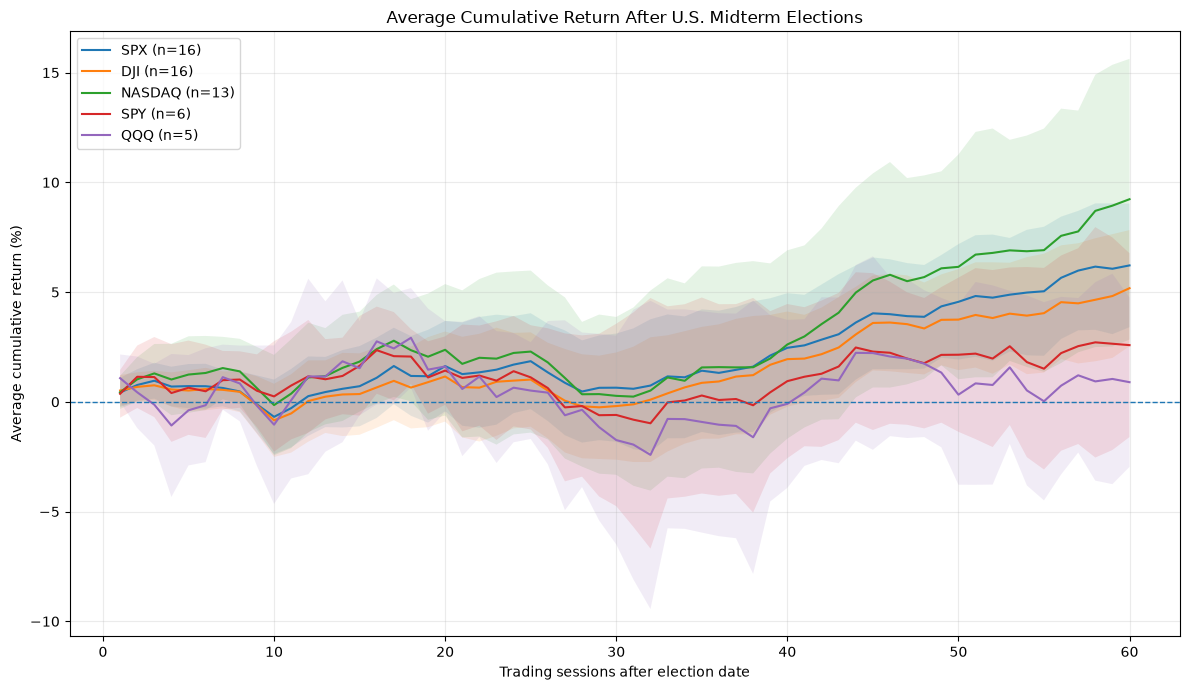

In [25]:

fig, ax = plt.subplots(figsize=(12, 7))

for asset in ["SPX", "DJI", "NASDAQ", "SPY", "QQQ"]:
    close = prices[asset]
    log_returns = np.log(close / close.shift(1)).dropna()
    event_paths = []

    for _, event in elections.iterrows():
        event_date = pd.Timestamp(event["election_date"]).normalize()

        if event_date < close.index.min():
            continue

        post = log_returns.loc[
            log_returns.index > event_date
        ].iloc[:60]

        if len(post) != 60:
            continue

        cumulative = np.expm1(post.cumsum()) * 100
        cumulative.index = np.arange(1, 61)
        event_paths.append(cumulative)

    if not event_paths:
        continue

    paths = pd.concat(event_paths, axis=1)
    mean_path = paths.mean(axis=1)
    n_by_day = paths.count(axis=1)

    if paths.shape[1] > 1:
        sem = paths.std(axis=1, ddof=1) / np.sqrt(n_by_day)
        lower = mean_path - 1.96 * sem
        upper = mean_path + 1.96 * sem
    else:
        lower = upper = pd.Series(np.nan, index=mean_path.index)

    ax.plot(
        mean_path.index,
        mean_path.values,
        label=f"{asset} (n={paths.shape[1]})"
    )

    if paths.shape[1] > 1:
        ax.fill_between(
            mean_path.index,
            lower.values,
            upper.values,
            alpha=0.12
        )

ax.axhline(0, linewidth=1, linestyle="--")
ax.set_title("Average Cumulative Return After U.S. Midterm Elections")
ax.set_xlabel("Trading sessions after election date")
ax.set_ylabel("Average cumulative return (%)")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "average_cumulative_return_path.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


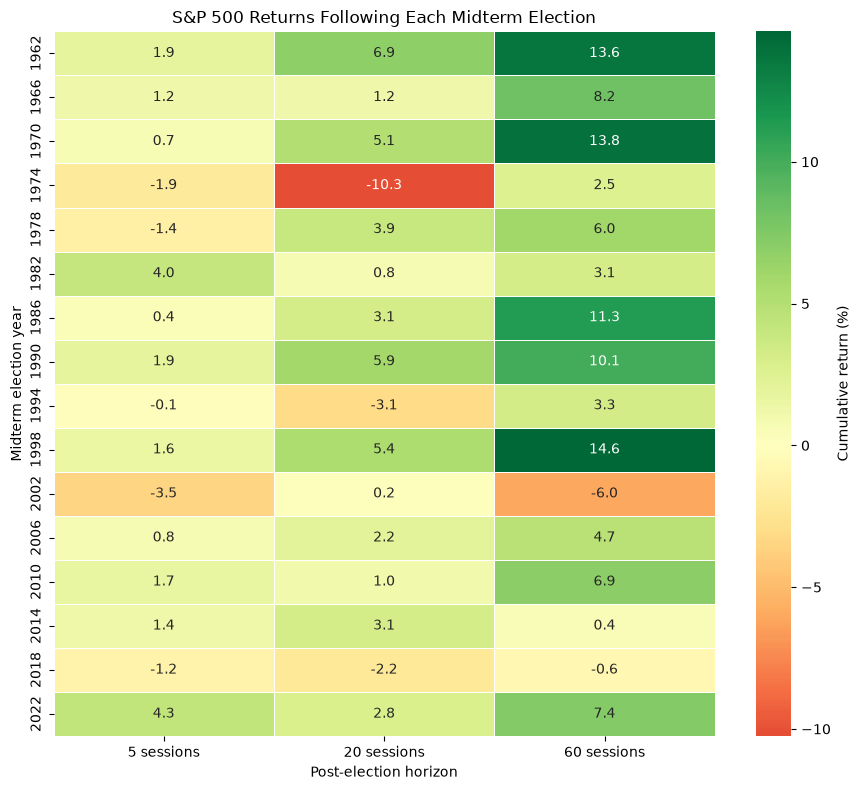

In [26]:

spx_heat = (
    event_panel[event_panel["asset"] == "SPX"]
    .set_index("year")[
        ["post5_return", "post20_return", "post60_return"]
    ]
    .rename(columns={
        "post5_return": "5 sessions",
        "post20_return": "20 sessions",
        "post60_return": "60 sessions",
    })
    .sort_index()
)

plt.figure(figsize=(9, 8))

sns.heatmap(
    spx_heat,
    annot=True,
    fmt=".1f",
    center=0,
    cmap="RdYlGn",
    linewidths=0.5,
    cbar_kws={"label": "Cumulative return (%)"},
)

plt.title("S&P 500 Returns Following Each Midterm Election")
plt.xlabel("Post-election horizon")
plt.ylabel("Midterm election year")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "spx_election_return_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


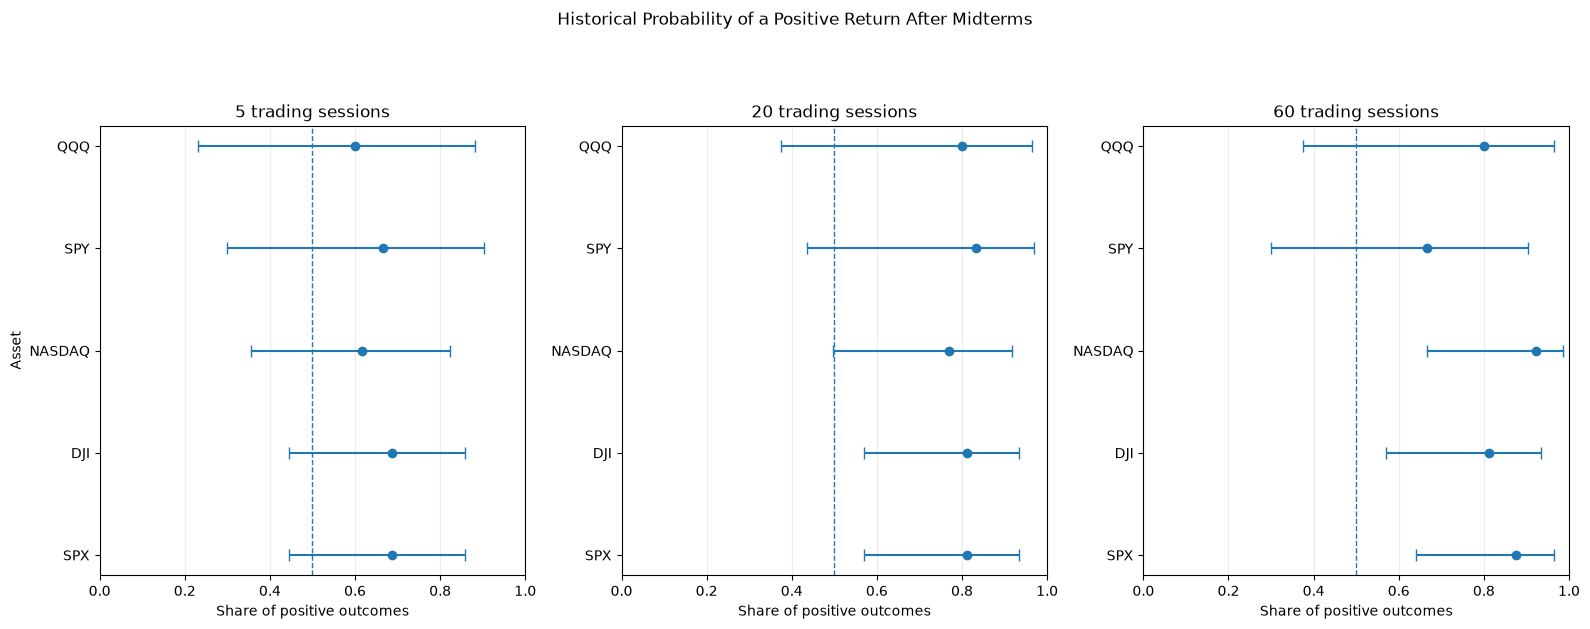

In [40]:

asset_order = ["SPX", "DJI", "NASDAQ", "SPY", "QQQ"]
horizon_order = [5, 20, 60]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 6),
    sharex=True
)

for ax, horizon in zip(axes, horizon_order):
    subset = probability_table[
        probability_table["horizon_sessions"] == horizon
    ].copy()

    subset["asset"] = pd.Categorical(
        subset["asset"],
        categories=asset_order,
        ordered=True
    )
    subset = subset.sort_values("asset")
    subset = subset.dropna(subset=["positive_probability"])

    y = np.arange(len(subset))
    p = subset["positive_probability"].to_numpy()
    lower = subset["ci95_low"].to_numpy()
    upper = subset["ci95_high"].to_numpy()

    ax.errorbar(
        p,
        y,
        xerr=np.vstack([p - lower, upper - p]),
        fmt="o",
        capsize=4
    )

    ax.set_yticks(y)
    ax.set_yticklabels(subset["asset"])
    ax.axvline(0.5, linestyle="--", linewidth=1)
    ax.set_xlim(0, 1)
    ax.set_title(f"{horizon} trading sessions")
    ax.set_xlabel("Share of positive outcomes")
    ax.grid(axis="x", alpha=0.25)

axes[0].set_ylabel("Asset")
fig.suptitle(
    "Historical Probability of a Positive Return After Midterms\n",
    y=1.04
)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "positive_probability_with_intervals.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


,asset,horizon_sessions,midterm_n,midterm_mean_pct,non_midterm_n,non_midterm_mean_pct,mean_difference_pp,welch_p_value
0,SPX,5,16,0.7164,50,0.2265,0.4899,0.4484
1,SPX,20,16,1.6290,50,0.9784,0.6506,0.5989
2,SPX,60,16,6.2163,50,2.4732,3.7431,0.0381
3,DJI,5,16,0.5147,50,0.3109,0.2037,0.7404
4,DJI,20,16,1.1540,50,1.1971,-0.0431,0.9725
5,DJI,60,16,5.1783,50,2.7624,2.4159,0.1521
6,NASDAQ,5,13,1.2430,42,0.2347,1.0083,0.3377
7,NASDAQ,20,13,2.3710,42,1.0650,1.3060,0.4839
8,NASDAQ,60,13,9.2326,42,3.9076,5.3251,0.1613
9,SPY,5,6,0.6432,20,0.2057,0.4375,0.7511


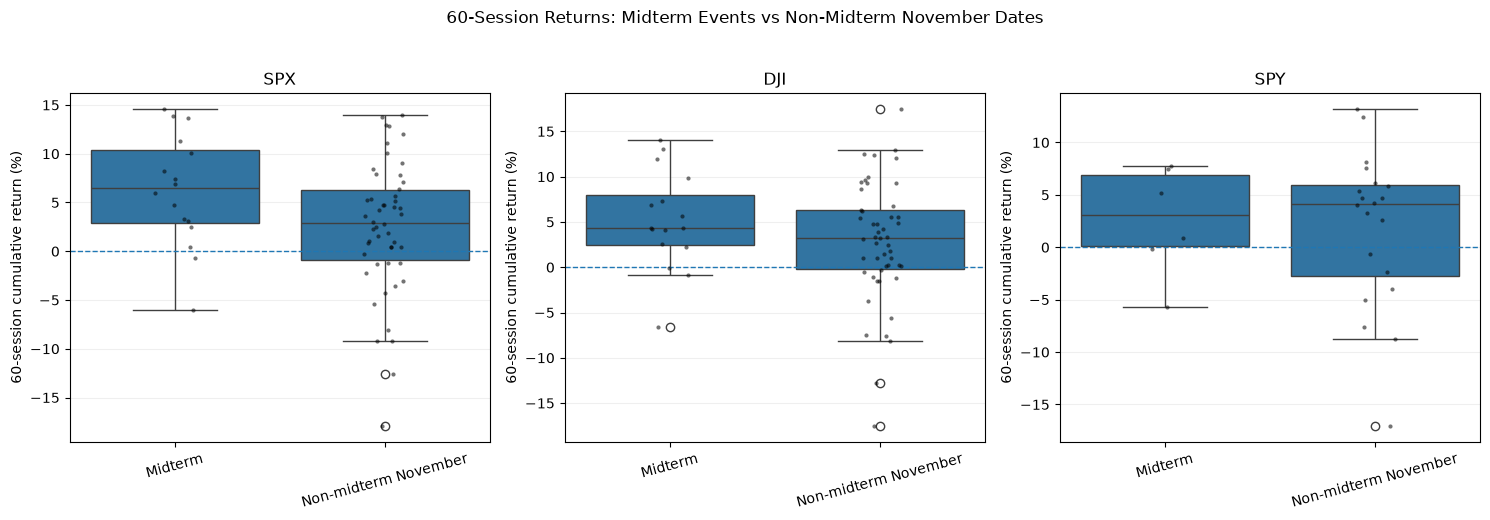

In [28]:

def first_tuesday_after_first_monday(year):
    november_first = pd.Timestamp(year=year, month=11, day=1)

    # Monday = 0. Find the first Monday in November.
    days_to_monday = (0 - november_first.weekday()) % 7
    first_monday = november_first + pd.Timedelta(days=days_to_monday)

    # Election day is the following Tuesday.
    return first_monday + pd.Timedelta(days=1)


last_data_year = max(close.index.max().year for close in prices.values())

control_rows = []

for year in range(1960, last_data_year + 1):
    # U.S. midterm election years are every fourth year, offset by two.
    if year % 4 == 2:
        continue

    control_date = first_tuesday_after_first_monday(year)

    for asset, close in prices.items():
        metrics = calculate_event(close, control_date)

        control_rows.append({
            "year": year,
            "election_date": control_date,
            "asset": asset,
            "group": "Non-midterm November",
            **metrics,
        })

control_panel = pd.DataFrame(control_rows)

midterm_panel = event_panel.copy()
midterm_panel["group"] = "Midterm"

comparison_panel = pd.concat(
    [midterm_panel, control_panel],
    ignore_index=True
)

# A comparison is valid only when the corresponding horizon is complete.
comparison_rows = []

for asset in prices:
    for horizon in HORIZONS:
        column = f"post{horizon}_return"

        mid = comparison_panel.loc[
            (comparison_panel["asset"] == asset)
            & (comparison_panel["group"] == "Midterm"),
            column
        ].dropna()

        control = comparison_panel.loc[
            (comparison_panel["asset"] == asset)
            & (comparison_panel["group"] == "Non-midterm November"),
            column
        ].dropna()

        mid_mean = mid.mean() if len(mid) else np.nan
        control_mean = control.mean() if len(control) else np.nan

        if len(mid) >= 2 and len(control) >= 2:
            welch_p = stats.ttest_ind(
                mid,
                control,
                equal_var=False,
                nan_policy="omit"
            ).pvalue
        else:
            welch_p = np.nan

        comparison_rows.append({
            "asset": asset,
            "horizon_sessions": horizon,
            "midterm_n": len(mid),
            "midterm_mean_pct": mid_mean,
            "non_midterm_n": len(control),
            "non_midterm_mean_pct": control_mean,
            "mean_difference_pp": mid_mean - control_mean,
            "welch_p_value": welch_p,
        })

comparison_summary = pd.DataFrame(comparison_rows)

display(comparison_summary.round(4))

comparison_panel.to_csv(
    OUTPUT_DIR / "midterm_and_control_event_panel.csv",
    index=False
)

comparison_summary.to_csv(
    OUTPUT_DIR / "midterm_vs_nonmidterm_comparison.csv",
    index=False
)

# Visual comparison of 60-session returns for the three main assets.
main_assets = ["SPX", "DJI", "SPY"]

fig, axes = plt.subplots(
    1, len(main_assets),
    figsize=(15, 5),
    sharey=False
)

for ax, asset in zip(axes, main_assets):
    plot_data = comparison_panel[
        (comparison_panel["asset"] == asset)
        & comparison_panel["post60_return"].notna()
    ].copy()

    sns.boxplot(
        data=plot_data,
        x="group",
        y="post60_return",
        ax=ax
    )

    sns.stripplot(
        data=plot_data,
        x="group",
        y="post60_return",
        ax=ax,
        color="black",
        alpha=0.55,
        size=3
    )

    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(asset)
    ax.set_xlabel("")
    ax.set_ylabel("60-session cumulative return (%)")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "60-Session Returns: Midterm Events vs Non-Midterm November Dates",
    y=1.03
)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "midterm_vs_control_60_session_returns.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


In [30]:

# Main benchmark: SPX
spx_probabilities = probability_table[
    probability_table["asset"] == "SPX"
].sort_values("horizon_sessions")

spx_summary = return_summary[
    return_summary["asset"] == "SPX"
].sort_values("horizon_sessions")

print("=" * 72)
print("U.S. MIDTERM ELECTIONS: HISTORICAL MARKET STUDY")
print("=" * 72)

print("\nS&P 500 — MAIN RESULTS")

for _, row in spx_probabilities.iterrows():
    horizon = int(row["horizon_sessions"])
    n = int(row["valid_events"])
    positive = int(row["positive_events"])

    mean_row = spx_summary[
        spx_summary["horizon_sessions"] == horizon
    ].iloc[0]

    if n:
        print(
            f"\nAfter {horizon} trading sessions:"
            f"\n  Positive outcomes: {positive}/{n}"
            f"\n  Historical positive frequency: "
            f"{row['positive_probability']:.1%}"
            f"\n  95% Wilson interval: "
            f"{row['ci95_low']:.1%} to {row['ci95_high']:.1%}"
            f"\n  Mean return: {mean_row['mean_return_pct']:+.2f}%"
            f"\n  Median return: {mean_row['median_return_pct']:+.2f}%"
            f"\n  Best observed return: {mean_row['best_return_pct']:+.2f}%"
            f"\n  Worst observed return: {mean_row['worst_return_pct']:+.2f}%"
        )
    else:
        print(f"\nAfter {horizon} sessions: no complete observations.")

print("\n\nCROSS-ASSET PROBABILITY TABLE")
display(
    display_probability.sort_values(
        ["horizon_sessions", "asset"]
    ).reset_index(drop=True)
)

print("\nMIDTERM VS NON-MIDTERM COMPARISON")
display(
    comparison_summary[
        comparison_summary["asset"].isin(["SPX", "DJI", "SPY"])
    ].round(4)
)

# Generate a stakeholder-ready text file directly from calculated results.
lines = [
    "U.S. MIDTERM ELECTIONS: HISTORICAL MARKET STUDY",
    "=" * 52,
    "",
    "Purpose",
    "Describe historical market returns after U.S. midterm elections.",
    "This is a descriptive historical study, not a causal analysis or a",
    "guaranteed forecast of the 2026 market.",
    "",
    "S&P 500 historical results",
]

for _, row in spx_probabilities.iterrows():
    horizon = int(row["horizon_sessions"])
    n = int(row["valid_events"])

    mean_row = spx_summary[
        spx_summary["horizon_sessions"] == horizon
    ].iloc[0]

    if n:
        lines.append(
            f"- {horizon} sessions: "
            f"{int(row['positive_events'])}/{n} positive "
            f"({row['positive_probability']:.1%}); "
            f"95% Wilson interval "
            f"{row['ci95_low']:.1%}-{row['ci95_high']:.1%}; "
            f"mean return {mean_row['mean_return_pct']:+.2f}%; "
            f"median {mean_row['median_return_pct']:+.2f}%."
        )

lines += [
    "",
    "Interpretation and limitations",
    "- Positive frequencies are historical sample proportions, not",
    "  calibrated probabilities that the next election will produce a gain.",
    "- Historical midterm events are few; individual outcomes vary.",
    "- The midterm versus non-midterm comparison is descriptive and does",
    "  not show that the election caused any return difference.",
    "- Asset histories differ. Missing or pre-inception windows are excluded.",
    "- SPX and DJI are index series; SPY and QQQ are ETF series.",
    "- The 2026 election is not a completed historical event in this study.",
    "",
    f"Historical events in the election file: {len(elections)}",
    f"Market data end dates: " + "; ".join(
        f"{asset}: {close.index.max().date()}"
        for asset, close in prices.items()
    ),
    "",
    f"Output directory: {OUTPUT_DIR}",
]

summary_text = "\n".join(lines)

print("\n\n" + summary_text)

with open(
    OUTPUT_DIR / "stakeholder_summary.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(summary_text)

# Save the coverage audit and the exact event dates used.
audit.to_csv(OUTPUT_DIR / "data_coverage_audit.csv", index=False)
elections.to_csv(OUTPUT_DIR / "election_events_used.csv", index=False)



U.S. MIDTERM ELECTIONS: HISTORICAL MARKET STUDY

S&P 500 — MAIN RESULTS

After 5 trading sessions:
  Positive outcomes: 11/16
  Historical positive frequency: 68.8%
  95% Wilson interval: 44.4% to 85.8%
  Mean return: +0.72%
  Median return: +0.97%
  Best observed return: +4.27%
  Worst observed return: -3.54%

After 20 trading sessions:
  Positive outcomes: 13/16
  Historical positive frequency: 81.2%
  95% Wilson interval: 57.0% to 93.4%
  Mean return: +1.63%
  Median return: +2.47%
  Best observed return: +6.92%
  Worst observed return: -10.25%

After 60 trading sessions:
  Positive outcomes: 14/16
  Historical positive frequency: 87.5%
  95% Wilson interval: 64.0% to 96.5%
  Mean return: +6.22%
  Median return: +6.48%
  Best observed return: +14.60%
  Worst observed return: -6.02%


CROSS-ASSET PROBABILITY TABLE


,asset,horizon_sessions,valid_events,positive_events,negative_events,flat_events,positive_probability,ci95_low,ci95_high
0,DJI,5,16,11,5,0,68.8,44.4,85.8
1,NASDAQ,5,13,8,5,0,61.5,35.5,82.3
2,QQQ,5,5,3,2,0,60.0,23.1,88.2
3,SPX,5,16,11,5,0,68.8,44.4,85.8
4,SPY,5,6,4,2,0,66.7,30.0,90.3
5,DJI,20,16,13,3,0,81.2,57.0,93.4
6,NASDAQ,20,13,10,3,0,76.9,49.7,91.8
7,QQQ,20,5,4,1,0,80.0,37.6,96.4
8,SPX,20,16,13,3,0,81.2,57.0,93.4
9,SPY,20,6,5,1,0,83.3,43.6,97.0



MIDTERM VS NON-MIDTERM COMPARISON


,asset,horizon_sessions,midterm_n,midterm_mean_pct,non_midterm_n,non_midterm_mean_pct,mean_difference_pp,welch_p_value
0,SPX,5,16,0.7164,50,0.2265,0.4899,0.4484
1,SPX,20,16,1.6290,50,0.9784,0.6506,0.5989
2,SPX,60,16,6.2163,50,2.4732,3.7431,0.0381
3,DJI,5,16,0.5147,50,0.3109,0.2037,0.7404
4,DJI,20,16,1.1540,50,1.1971,-0.0431,0.9725
5,DJI,60,16,5.1783,50,2.7624,2.4159,0.1521
9,SPY,5,6,0.6432,20,0.2057,0.4375,0.7511
10,SPY,20,6,1.4247,20,1.2555,0.1692,0.9011
11,SPY,60,6,2.5833,20,1.8339,0.7494,0.7868




U.S. MIDTERM ELECTIONS: HISTORICAL MARKET STUDY

Purpose
Describe historical market returns after U.S. midterm elections.
This is a descriptive historical study, not a causal analysis or a
guaranteed forecast of the 2026 market.

S&P 500 historical results
- 5 sessions: 11/16 positive (68.8%); 95% Wilson interval 44.4%-85.8%; mean return +0.72%; median +0.97%.
- 20 sessions: 13/16 positive (81.2%); 95% Wilson interval 57.0%-93.4%; mean return +1.63%; median +2.47%.
- 60 sessions: 14/16 positive (87.5%); 95% Wilson interval 64.0%-96.5%; mean return +6.22%; median +6.48%.

Interpretation and limitations
- Positive frequencies are historical sample proportions, not
  calibrated probabilities that the next election will produce a gain.
- Historical midterm events are few; individual outcomes vary.
- The midterm versus non-midterm comparison is descriptive and does
  not show that the election caused any return difference.
- Asset histories differ. Missing or pre-inception windows are exc

In [31]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import binomtest, wilcoxon
from IPython.display import display

OUTPUT_DIR = Path("data/processed/midterm_final_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ASSETS = ["SPX", "DJI", "NASDAQ", "SPY"]
HORIZONS = [5, 10, 20, 60]

# Exclude QQQ completely.
prices = {asset: prices[asset] for asset in ASSETS}

# Keep the historical midterm events only.
elections = elections.copy()
elections["election_date"] = pd.to_datetime(
    elections["election_date"]
).dt.normalize()

if "event_type" in elections.columns:
    mask = elections["event_type"].astype(str).str.contains(
        "midterm", case=False, na=False
    )
    if mask.any():
        elections = elections.loc[mask].copy()

elections = (
    elections.sort_values("election_date")
    .drop_duplicates("election_date")
    .reset_index(drop=True)
)

def event_metrics(close, election_date):
    """
    Anchor price: last available close on or before election date.
    Post-election return: anchor close to close after h subsequent
    trading sessions.

    The first post-election return ends on the first trading session
    strictly after election date.
    """
    close = close.dropna().sort_index()
    close = close[~close.index.duplicated(keep="last")]

    election_date = pd.Timestamp(election_date).normalize()

    out = {
        "anchor_date": pd.NaT,
        "anchor_close": np.nan,
        "first_post_date": pd.NaT,
        "pre20_return": np.nan,
        "pre20_rv": np.nan,
        "post20_rv": np.nan,
        "rv_change_pp": np.nan,
    }

    for h in HORIZONS:
        out[f"post{h}_return"] = np.nan
        out[f"post{h}_end_date"] = pd.NaT

    # An asset must already have a price history by the event date.
    if close.empty or close.index.min() > election_date:
        return out

    anchor_candidates = close.loc[close.index <= election_date]
    post_prices = close.loc[close.index > election_date]

    if anchor_candidates.empty:
        return out

    anchor_date = anchor_candidates.index[-1]
    anchor_close = float(anchor_candidates.iloc[-1])

    out["anchor_date"] = anchor_date
    out["anchor_close"] = anchor_close

    if len(post_prices):
        out["first_post_date"] = post_prices.index[0]

    # Daily log returns, indexed by the date on which each return ends.
    log_returns = np.log(close / close.shift(1)).dropna()

    # Pre-election volatility: last 20 daily returns ending on or
    # before the anchor close.
    pre_returns = log_returns.loc[log_returns.index <= anchor_date]
    if len(pre_returns) >= 20:
        pre20 = pre_returns.iloc[-20:]
        out["pre20_return"] = np.expm1(pre20.sum()) * 100
        out["pre20_rv"] = np.sqrt(np.square(pre20).sum()) * 100

    # Post-election daily returns end strictly after the election date.
    post_returns = log_returns.loc[log_returns.index > election_date]

    for h in HORIZONS:
        if len(post_prices) >= h:
            end_date = post_prices.index[h - 1]
            end_close = float(post_prices.iloc[h - 1])

            out[f"post{h}_return"] = (
                end_close / anchor_close - 1
            ) * 100

            out[f"post{h}_end_date"] = end_date

    if len(post_returns) >= 20:
        post20 = post_returns.iloc[:20]
        out["post20_rv"] = np.sqrt(np.square(post20).sum()) * 100

    if pd.notna(out["pre20_rv"]) and pd.notna(out["post20_rv"]):
        out["rv_change_pp"] = out["post20_rv"] - out["pre20_rv"]

    return out


rows = []

for _, election in elections.iterrows():
    for asset, close in prices.items():
        metrics = event_metrics(close, election["election_date"])

        rows.append({
            "year": int(election["election_date"].year),
            "election_date": election["election_date"],
            "asset": asset,
            **metrics,
        })

event_panel = pd.DataFrame(rows)

assert not event_panel.duplicated(["year", "asset"]).any()

# Hard checks: do not report events before the asset's inception.
for asset, close in prices.items():
    invalid = event_panel[
        (event_panel["asset"] == asset)
        & (event_panel["election_date"] < close.index.min())
    ]
    cols = [f"post{h}_return" for h in HORIZONS]
    assert invalid[cols].isna().all().all()

coverage = event_panel.groupby("asset").agg(
    elections=("year", "nunique"),
    **{
        f"valid_post{h}": (f"post{h}_return", "count")
        for h in HORIZONS
    }
).reset_index()

display(coverage)
display(
    event_panel[event_panel["asset"] == "SPX"][
        ["year", "election_date", "anchor_date",
         "first_post_date", "post5_return", "post10_return",
         "post20_return", "post60_return"]
    ].round(3)
)

event_panel.to_csv(
    OUTPUT_DIR / "per_election_event_panel.csv",
    index=False
)

print("Per-election event panel rebuilt.")


,asset,elections,valid_post5,valid_post10,valid_post20,valid_post60
0,DJI,16,16,16,16,16
1,NASDAQ,16,13,13,13,13
2,SPX,16,16,16,16,16
3,SPY,16,6,6,6,6


C:\Users\JM2090\AppData\Local\Temp\ipykernel_26136\1332036559.py:161: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,year,election_date,anchor_date,first_post_date,post5_return,post10_return,post20_return,post60_return
0,1962,1962-11-06,1962-11-05,1962-11-07,1.902,3.599,6.924,13.642
4,1966,1966-11-08,1966-11-07,1966-11-09,1.189,-1.313,1.226,8.213
8,1970,1970-11-03,1970-11-03,1970-11-04,0.677,-0.891,5.058,13.845
12,1974,1974-11-05,1974-11-05,1974-11-06,-1.917,-9.200,-10.252,2.490
16,1978,1978-11-07,1978-11-07,1978-11-08,-1.449,1.236,3.879,6.020
20,1982,1982-11-02,1982-11-02,1982-11-03,4.022,-1.513,0.756,3.091
24,1986,1986-11-04,1986-11-04,1986-11-05,0.357,-3.826,3.107,11.324
28,1990,1990-11-06,1990-11-06,1990-11-07,1.941,1.184,5.873,10.086
32,1994,1994-11-08,1994-11-08,1994-11-09,-0.133,-3.344,-3.097,3.337
36,1998,1998-11-03,1998-11-03,1998-11-04,1.568,2.564,5.438,14.601


Per-election event panel rebuilt.


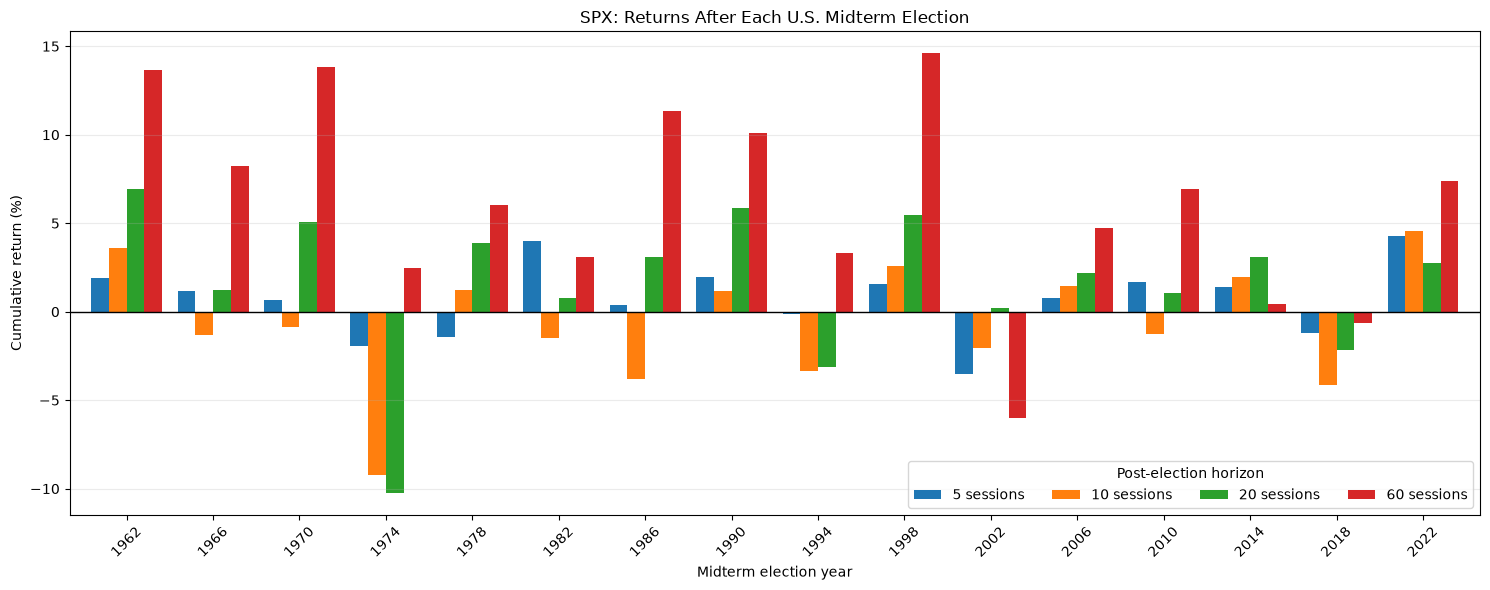

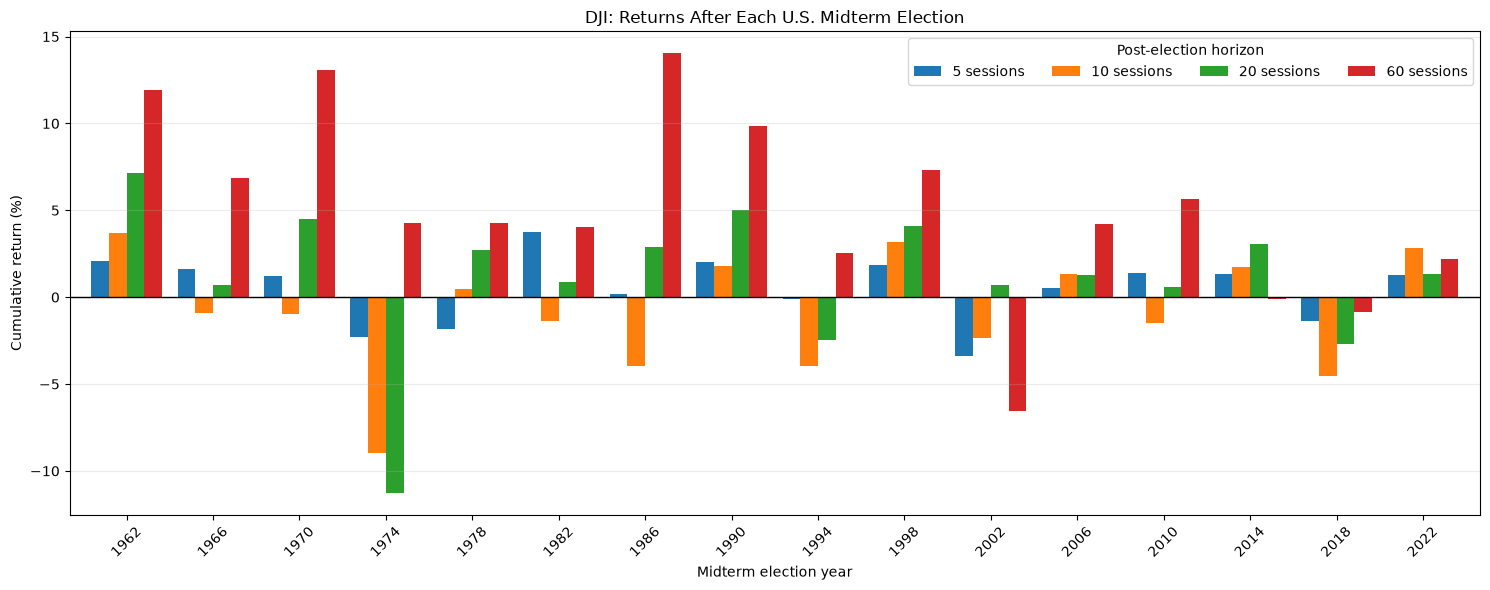

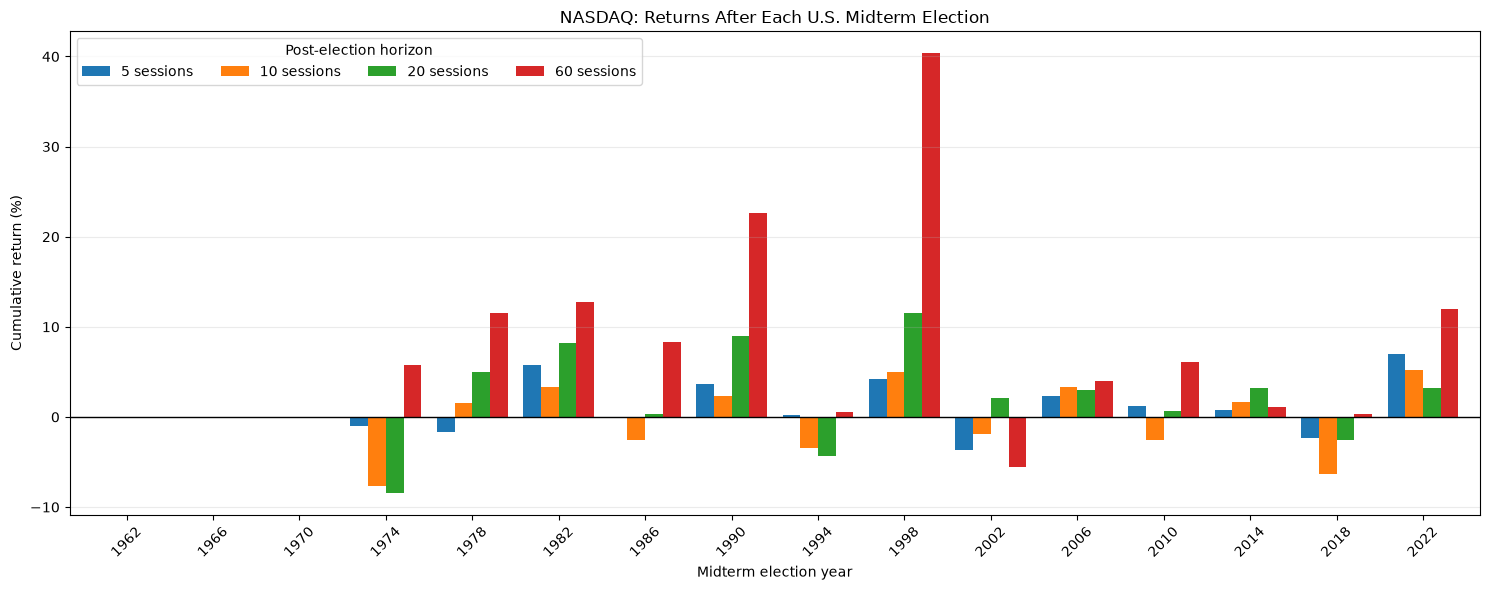

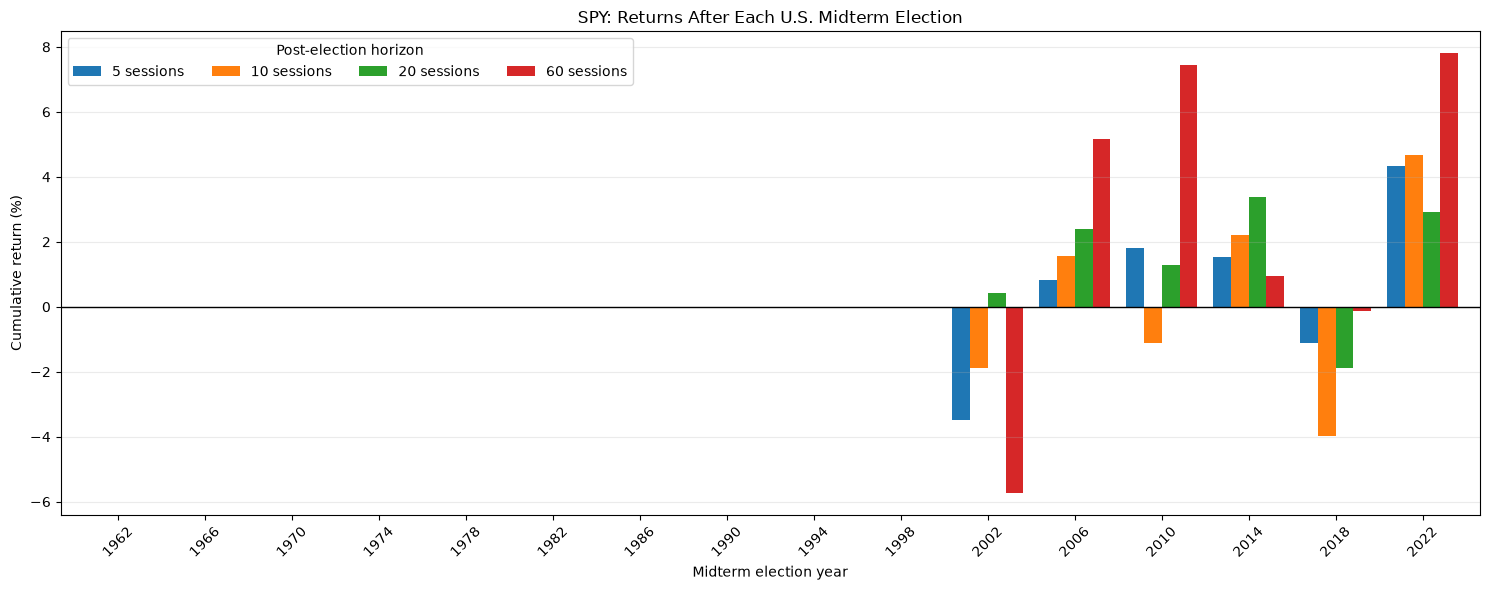

In [32]:
for asset in ASSETS:
    subset = (
        event_panel[event_panel["asset"] == asset]
        .sort_values("year")
        .set_index("year")
    )

    plot_cols = [f"post{h}_return" for h in HORIZONS]
    plot_data = subset[plot_cols].copy()
    plot_data.columns = [f"{h} sessions" for h in HORIZONS]

    ax = plot_data.plot(
        kind="bar",
        figsize=(15, 6),
        width=0.82
    )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(
        f"{asset}: Returns After Each U.S. Midterm Election"
    )
    ax.set_xlabel("Midterm election year")
    ax.set_ylabel("Cumulative return (%)")
    ax.legend(title="Post-election horizon", ncols=4)
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"{asset.lower()}_per_election_returns.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


In [41]:
event_panel.columns

Index(['year', 'election_date', 'asset', 'anchor_date', 'anchor_close',
       'first_post_date', 'pre20_return', 'pre20_rv', 'post20_rv',
       'rv_change_pp', 'post5_return', 'post5_end_date', 'post10_return',
       'post10_end_date', 'post20_return', 'post20_end_date', 'post60_return',
       'post60_end_date'],
      dtype='str')

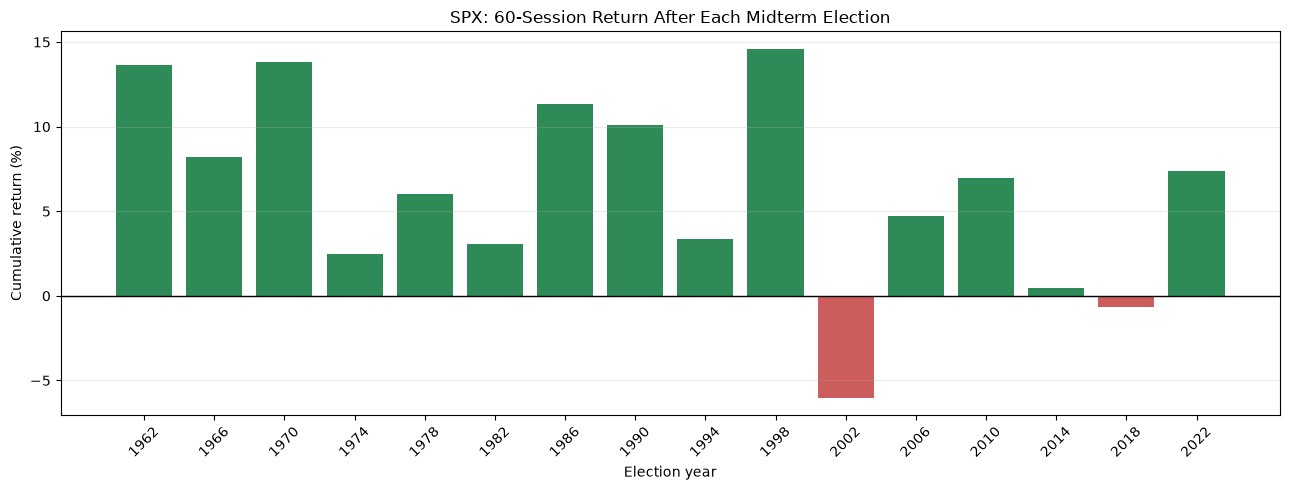

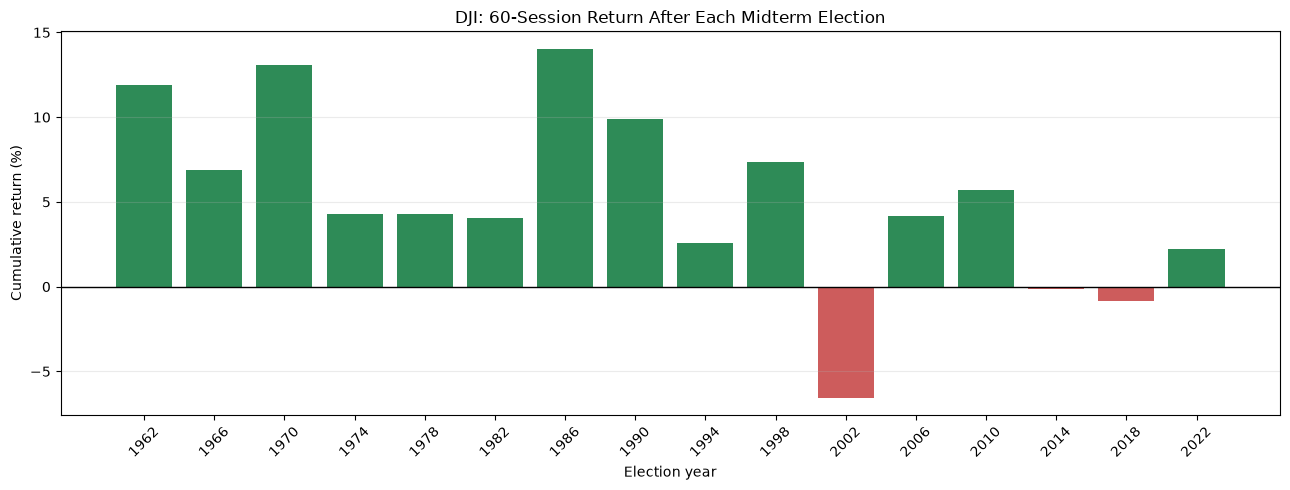

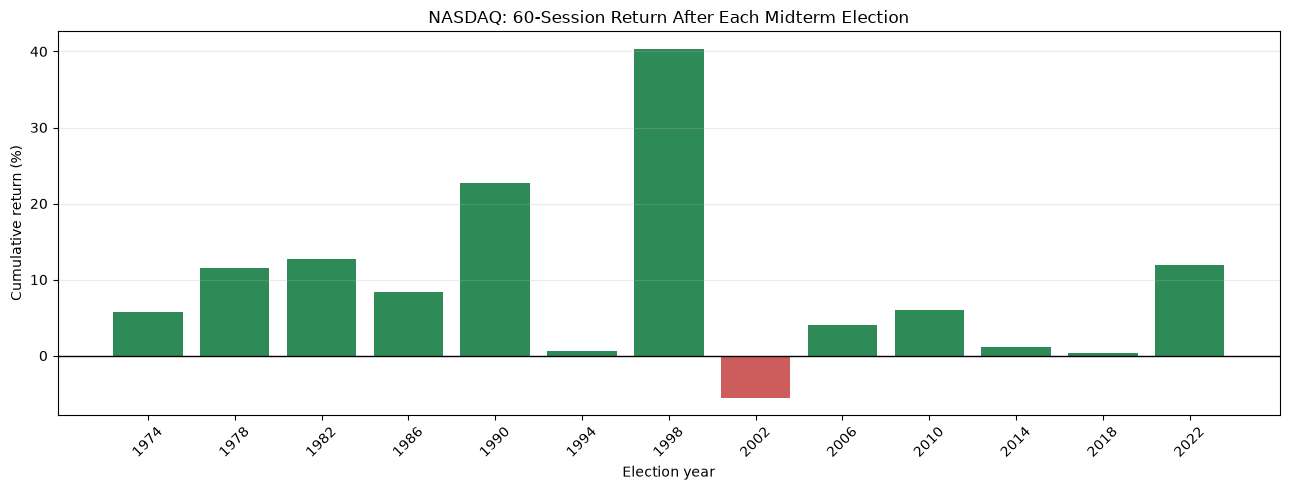

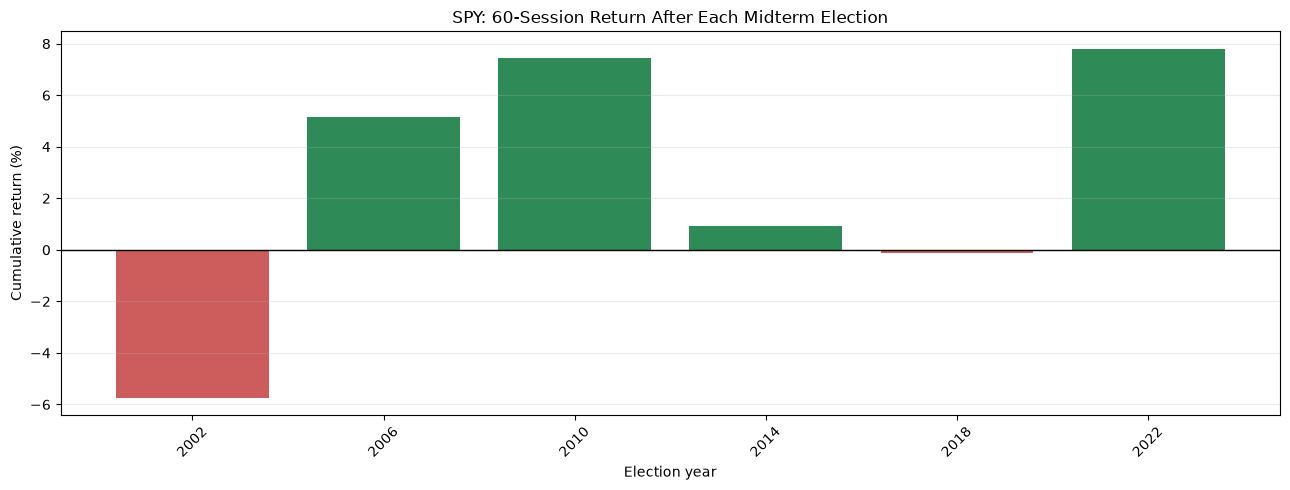

In [33]:
for asset in ASSETS:
    subset = (
        event_panel[event_panel["asset"] == asset]
        .sort_values("year")
        .dropna(subset=["post60_return"])
    )

    if subset.empty:
        continue

    colors = [
        "seagreen" if value > 0 else "indianred"
        for value in subset["post60_return"]
    ]

    fig, ax = plt.subplots(figsize=(13, 5))
    ax.bar(
        subset["year"].astype(str),
        subset["post60_return"],
        color=colors
    )
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(
        f"{asset}: 60-Session Return After Each Midterm Election"
    )
    ax.set_xlabel("Election year")
    ax.set_ylabel("Cumulative return (%)")
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"{asset.lower()}_post60_by_election.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


In [34]:

from scipy.stats import ttest_1samp, binomtest, wilcoxon

def wilson_interval(successes, n, z=1.959963984540054):
    if n == 0:
        return np.nan, np.nan

    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(
        p * (1 - p) / n + z**2 / (4 * n**2)
    ) / denom

    return center - half, center + half


test_rows = []

for asset in ASSETS:
    asset_data = event_panel[event_panel["asset"] == asset]

    for h in HORIZONS:
        col = f"post{h}_return"
        returns = asset_data[col].dropna()

        n = len(returns)
        positive = int((returns > 0).sum())
        negative = int((returns < 0).sum())
        zero = int((returns == 0).sum())

        ci_low, ci_high = wilson_interval(positive, n)

        # Binomial sign test: ignore exact ties, test positive vs negative.
        nonzero = returns[returns != 0]
        n_nonzero = len(nonzero)
        n_positive_nonzero = int((nonzero > 0).sum())

        if n_nonzero:
            sign_p = binomtest(
                n_positive_nonzero,
                n_nonzero,
                p=0.5,
                alternative="two-sided"
            ).pvalue
        else:
            sign_p = np.nan

        # One-sample t-test: mean return versus zero.
        if n >= 2:
            t_result = ttest_1samp(returns, popmean=0)
            t_stat = t_result.statistic
            t_p = t_result.pvalue
        else:
            t_stat = np.nan
            t_p = np.nan

        # Wilcoxon signed-rank: tests whether paired differences
        # (here, returns minus zero) are centred around zero.
        # It is a different test from the Wilson confidence interval.
        if n_nonzero >= 2:
            try:
                w_result = wilcoxon(
                    returns,
                    zero_method="wilcox",
                    alternative="two-sided",
                    method="auto"
                )
                w_stat = w_result.statistic
                w_p = w_result.pvalue
            except ValueError:
                w_stat = np.nan
                w_p = np.nan
        else:
            w_stat = np.nan
            w_p = np.nan

        test_rows.append({
            "asset": asset,
            "horizon_sessions": h,
            "n": n,
            "positive_n": positive,
            "negative_n": negative,
            "zero_n": zero,
            "positive_rate": positive / n if n else np.nan,
            "wilson95_low": ci_low,
            "wilson95_high": ci_high,
            "mean_return_pct": returns.mean() if n else np.nan,
            "median_return_pct": returns.median() if n else np.nan,
            "t_statistic": t_stat,
            "t_test_p": t_p,
            "sign_test_p": sign_p,
            "wilcoxon_statistic": w_stat,
            "wilcoxon_p": w_p,
        })

tests = pd.DataFrame(test_rows)

# Adjust p-values for multiple comparisons using Holm's procedure.
# Adjust each test family separately across all asset/horizon combinations.
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(len(p_values), np.nan)

    valid_idx = np.where(np.isfinite(p_values))[0]
    if len(valid_idx) == 0:
        return adjusted

    valid_p = p_values[valid_idx]
    order = np.argsort(valid_p)
    sorted_p = valid_p[order]
    m = len(sorted_p)

    sorted_adj = np.maximum.accumulate(
        [(m - i) * p for i, p in enumerate(sorted_p)]
    )
    sorted_adj = np.clip(sorted_adj, 0, 1)

    original_positions = valid_idx[order]
    adjusted[original_positions] = sorted_adj
    return adjusted


for p_col in ["t_test_p", "sign_test_p", "wilcoxon_p"]:
    tests[p_col.replace("_p", "_holm_p")] = holm_adjust(
        tests[p_col].to_numpy()
    )

display(
    tests.sort_values(["asset", "horizon_sessions"]).round(4)
)

tests.to_csv(
    OUTPUT_DIR / "statistical_tests_all_assets.csv",
    index=False
)

print("Statistical tests saved.")


,asset,horizon_sessions,n,positive_n,negative_n,zero_n,positive_rate,wilson95_low,wilson95_high,mean_return_pct,median_return_pct,t_statistic,t_test_p,sign_test_p,wilcoxon_statistic,wilcoxon_p,t_test_holm_p,sign_test_holm_p,wilcoxon_holm_p
4,DJI,5,16,11,5,0,0.6875,0.4440,0.8584,0.5147,1.2576,1.0926,0.2918,0.2101,48.0,0.3225,1.0000,1.0000,1.0000
5,DJI,10,16,7,9,0,0.4375,0.2310,0.6682,-0.8433,-0.9460,-0.9917,0.3371,0.8036,53.0,0.4637,1.0000,1.0000,1.0000
6,DJI,20,16,13,3,0,0.8125,0.5699,0.9341,1.1540,1.2862,1.1020,0.2878,0.0213,31.0,0.0577,1.0000,0.2978,0.6921
7,DJI,60,16,13,3,0,0.8125,0.5699,0.9341,5.1783,4.2918,3.8333,0.0016,0.0213,13.0,0.0027,0.0244,0.2978,0.0376
8,NASDAQ,5,13,8,5,0,0.6154,0.3552,0.8229,1.2430,0.7985,1.3974,0.1876,0.5811,29.0,0.2734,1.0000,1.0000,1.0000
9,NASDAQ,10,13,7,6,0,0.5385,0.2914,0.7679,-0.1483,1.5333,-0.1271,0.9010,1.0000,43.0,0.8926,1.0000,1.0000,1.0000
10,NASDAQ,20,13,10,3,0,0.7692,0.4974,0.9182,2.3710,2.9454,1.5521,0.1466,0.0923,23.0,0.1272,1.0000,1.0000,1.0000
11,NASDAQ,60,13,12,1,0,0.9231,0.6669,0.9863,9.2326,6.0536,2.8296,0.0152,0.0034,5.0,0.0024,0.2126,0.0547,0.0366
0,SPX,5,16,11,5,0,0.6875,0.4440,0.8584,0.7164,0.9699,1.3972,0.1827,0.2101,41.0,0.1754,1.0000,1.0000,1.0000
1,SPX,10,16,7,9,0,0.4375,0.2310,0.6682,-0.6836,-1.0833,-0.7893,0.4422,0.8036,56.0,0.5619,1.0000,1.0000,1.0000


Statistical tests saved.


,asset,year,pre20_rv,post20_rv,rv_change_pp
0,SPX,1962,5.763,3.306,-2.457
1,SPX,1966,3.950,2.980,-0.970
2,SPX,1970,2.782,3.115,0.334
3,SPX,1974,9.336,6.018,-3.318
4,SPX,1978,6.315,3.948,-2.367
5,SPX,1982,7.920,8.333,0.414
6,SPX,1986,3.032,4.552,1.520
7,SPX,1990,5.669,4.600,-1.069
8,SPX,1994,2.909,2.814,-0.094
9,SPX,1998,6.184,4.358,-1.827


,asset,paired_events,volatility_increased,volatility_decreased,mean_pre20_rv_pct,mean_post20_rv_pct,mean_change_pp,median_change_pp,paired_ttest_p,paired_wilcoxon_p,increase_decrease_sign_p
0,SPX,16,6,10,5.4009,4.5405,-0.8603,-0.8424,0.0573,0.0833,0.4545
1,DJI,16,5,11,5.3876,4.4565,-0.9311,-0.6991,0.0523,0.0739,0.2101
2,NASDAQ,13,4,9,6.1782,5.4109,-0.7673,-0.3190,0.1785,0.2734,0.2668
3,SPY,6,3,3,5.3657,4.7535,-0.6122,-0.1930,0.5012,0.5625,1.0000


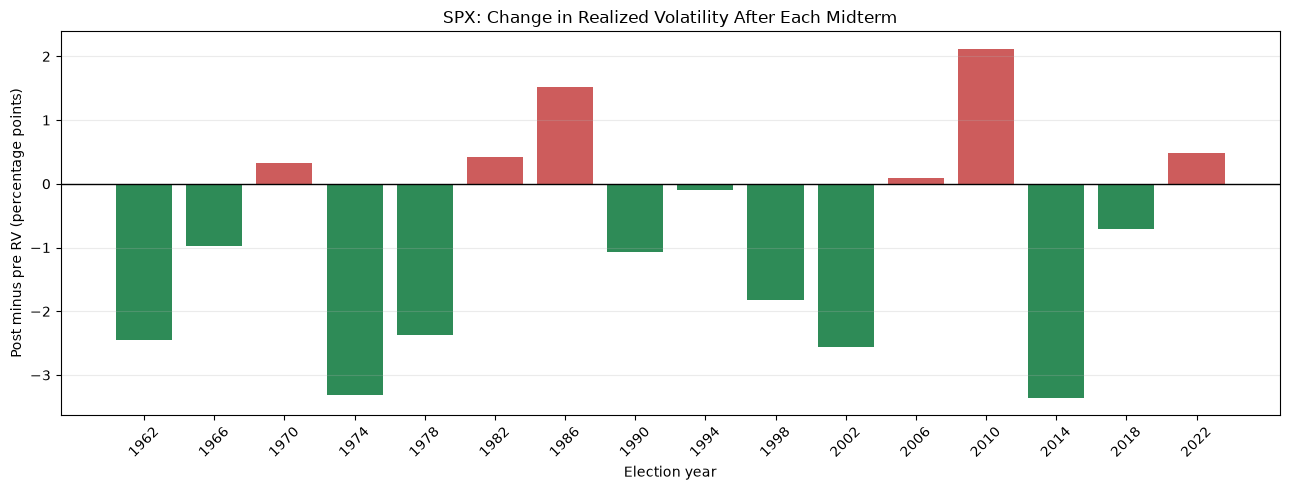

In [36]:

rv_rows = []

for asset in ASSETS:
    subset = event_panel[event_panel["asset"] == asset].copy()

    for _, row in subset.iterrows():
        if pd.isna(row["pre20_rv"]) or pd.isna(row["post20_rv"]):
            continue

        rv_rows.append({
            "asset": asset,
            "year": row["year"],
            "pre20_rv": row["pre20_rv"],
            "post20_rv": row["post20_rv"],
            "rv_change_pp": row["post20_rv"] - row["pre20_rv"],
        })

rv_panel = pd.DataFrame(rv_rows)

display(rv_panel.round(3))

rv_test_rows = []

for asset in ASSETS:
    subset = rv_panel[rv_panel["asset"] == asset]
    pre = subset["pre20_rv"].dropna()
    post = subset["post20_rv"].dropna()

    paired = subset.dropna(subset=["pre20_rv", "post20_rv"])
    changes = paired["rv_change_pp"]

    if len(paired) >= 2:
        paired_t_p = stats.ttest_rel(
            paired["post20_rv"], paired["pre20_rv"]
        ).pvalue

        try:
            paired_wilcoxon_p = wilcoxon(
                paired["post20_rv"],
                paired["pre20_rv"],
                zero_method="wilcox",
                method="auto"
            ).pvalue
        except ValueError:
            paired_wilcoxon_p = np.nan

        nonzero = changes[changes != 0]
        if len(nonzero):
            increase_sign_p = binomtest(
                int((nonzero > 0).sum()),
                len(nonzero),
                p=0.5,
                alternative="two-sided"
            ).pvalue
        else:
            increase_sign_p = np.nan

        rv_test_rows.append({
            "asset": asset,
            "paired_events": len(paired),
            "volatility_increased": int((changes > 0).sum()),
            "volatility_decreased": int((changes < 0).sum()),
            "mean_pre20_rv_pct": paired["pre20_rv"].mean(),
            "mean_post20_rv_pct": paired["post20_rv"].mean(),
            "mean_change_pp": changes.mean(),
            "median_change_pp": changes.median(),
            "paired_ttest_p": paired_t_p,
            "paired_wilcoxon_p": paired_wilcoxon_p,
            "increase_decrease_sign_p": increase_sign_p,
        })

rv_tests = pd.DataFrame(rv_test_rows)
display(rv_tests.round(4))

rv_panel.to_csv(
    OUTPUT_DIR / "per_election_realized_volatility.csv",
    index=False
)
rv_tests.to_csv(
    OUTPUT_DIR / "realized_volatility_tests.csv",
    index=False
)


# Bar chart of the volatility change by election.
fig, ax = plt.subplots(figsize=(13, 5))
colors = [
    "seagreen" if x < 0 else "indianred"
    for x in spx_rv["rv_change_pp"]
]

ax.bar(
    spx_rv["year"].astype(str),
    spx_rv["rv_change_pp"],
    color=colors
)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("SPX: Change in Realized Volatility After Each Midterm")
ax.set_ylabel("Post minus pre RV (percentage points)")
ax.set_xlabel("Election year")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "spx_volatility_change_by_election.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


In [37]:

negative_rows = []

for _, row in event_panel.iterrows():
    for h in HORIZONS:
        col = f"post{h}_return"
        value = row[col]

        if pd.notna(value) and value < 0:
            negative_rows.append({
                "asset": row["asset"],
                "year": row["year"],
                "election_date": row["election_date"],
                "horizon_sessions": h,
                "window_end_date": row[f"post{h}_end_date"],
                "return_pct": value,
                "pre20_rv": row["pre20_rv"],
                "post20_rv": row["post20_rv"],
                "rv_change_pp": row["rv_change_pp"],
            })

negative_windows = pd.DataFrame(negative_rows)

if negative_windows.empty:
    print("No negative complete windows found.")
else:
    negative_windows = negative_windows.sort_values(
        ["asset", "horizon_sessions", "year"]
    )

    display(negative_windows.round(3))

negative_windows.to_csv(
    OUTPUT_DIR / "all_negative_election_windows.csv",
    index=False
)

# SPX-specific summary: how many negative outcomes at each horizon?
spx_negative_summary = []

for h in HORIZONS:
    col = f"post{h}_return"
    returns = event_panel.loc[
        event_panel["asset"] == "SPX", col
    ].dropna()

    spx_negative_summary.append({
        "horizon_sessions": h,
        "valid_events": len(returns),
        "negative_n": int((returns < 0).sum()),
        "negative_rate": float((returns < 0).mean()) if len(returns) else np.nan,
        "positive_n": int((returns > 0).sum()),
        "positive_rate": float((returns > 0).mean()) if len(returns) else np.nan,
    })

display(pd.DataFrame(spx_negative_summary).round(3))


C:\Users\JM2090\AppData\Local\Temp\ipykernel_26136\3610533065.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(negative_windows.round(3))


,asset,year,election_date,horizon_sessions,window_end_date,return_pct,pre20_rv,post20_rv,rv_change_pp
7,DJI,1974,1974-11-05,5,1974-11-12,-2.308,9.727,5.953,-3.775
14,DJI,1978,1978-11-07,5,1978-11-14,-1.851,7.084,4.448,-2.636
25,DJI,1994,1994-11-08,5,1994-11-15,-0.114,2.890,3.621,0.731
33,DJI,2002,2002-11-05,5,2002-11-12,-3.368,9.741,6.263,-3.478
51,DJI,2018,2018-11-06,5,2018-11-13,-1.360,6.369,6.363,-0.005
...,...,...,...,...,...,...,...,...,...
45,SPY,2010,2010-11-02,10,2010-11-16,-1.105,2.435,4.664,2.229
59,SPY,2018,2018-11-06,10,2018-11-20,-3.966,6.818,6.190,-0.628
60,SPY,2018,2018-11-06,20,2018-12-06,-1.879,6.818,6.190,-0.628
41,SPY,2002,2002-11-05,60,2003-02-03,-5.737,9.119,6.406,-2.713


,horizon_sessions,valid_events,negative_n,negative_rate,positive_n,positive_rate
0,5,16,5,0.312,11,0.688
1,10,16,9,0.562,7,0.438
2,20,16,3,0.188,13,0.812
3,60,16,2,0.125,14,0.875


In [38]:

wide_returns = event_panel.pivot(
    index="year",
    columns="asset",
    values=[f"post{h}_return" for h in HORIZONS]
)

wide_returns.columns = [
    f"{asset}_{column.replace('post', '')}"
    for column, asset in wide_returns.columns
]

wide_returns = wide_returns.reset_index()
display(wide_returns.round(3))

wide_returns.to_csv(
    OUTPUT_DIR / "per_election_return_pivot.csv",
    index=False
)

# Also save a compact SPX-only table, suitable for a presentation appendix.
spx_appendix = event_panel[
    event_panel["asset"] == "SPX"
][[
    "year", "election_date", "anchor_date", "anchor_close",
    "first_post_date",
    "post5_return", "post5_end_date",
    "post10_return", "post10_end_date",
    "post20_return", "post20_end_date",
    "post60_return", "post60_end_date",
    "pre20_rv", "post20_rv", "rv_change_pp",
]].sort_values("year")

display(spx_appendix.round(3))

spx_appendix.to_csv(
    OUTPUT_DIR / "spx_election_outcomes_appendix.csv",
    index=False
)

print(f"Finished. Results saved under: {OUTPUT_DIR.resolve()}")


,year,DJI_5_return,NASDAQ_5_return,SPX_5_return,SPY_5_return,DJI_10_return,NASDAQ_10_return,SPX_10_return,SPY_10_return,DJI_20_return,NASDAQ_20_return,SPX_20_return,SPY_20_return,DJI_60_return,NASDAQ_60_return,SPX_60_return,SPY_60_return
0,1962,2.069,NaN,1.902,NaN,3.679,NaN,3.599,NaN,7.127,NaN,6.924,NaN,11.910,NaN,13.642,NaN
1,1966,1.632,NaN,1.189,NaN,-0.902,NaN,-1.313,NaN,0.722,NaN,1.226,NaN,6.886,NaN,8.213,NaN
2,1970,1.212,NaN,0.677,NaN,-0.989,NaN,-0.891,NaN,4.501,NaN,5.058,NaN,13.076,NaN,13.845,NaN
3,1974,-2.308,-0.955,-1.917,NaN,-8.996,-7.668,-9.200,NaN,-11.280,-8.456,-10.252,NaN,4.289,5.743,2.490,NaN
4,1978,-1.851,-1.728,-1.449,NaN,0.497,1.533,1.236,NaN,2.729,4.981,3.879,NaN,4.295,11.513,6.020,NaN
5,1982,3.735,5.762,4.022,NaN,-1.377,3.363,-1.513,NaN,0.882,8.243,0.756,NaN,4.066,12.768,3.091,NaN
6,1986,0.190,-0.166,0.357,NaN,-3.974,-2.570,-3.826,NaN,2.901,0.304,3.107,NaN,14.035,8.345,11.324,NaN
7,1990,2.024,3.642,1.941,NaN,1.815,2.291,1.184,NaN,5.042,8.928,5.873,NaN,9.879,22.673,10.086,NaN
8,1994,-0.114,0.195,-0.133,NaN,-3.987,-3.427,-3.344,NaN,-2.486,-4.326,-3.097,NaN,2.556,0.599,3.337,NaN
9,1998,1.825,4.208,1.568,NaN,3.194,5.013,2.564,NaN,4.108,11.551,5.438,NaN,7.346,40.352,14.601,NaN


C:\Users\JM2090\AppData\Local\Temp\ipykernel_26136\2400135180.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(spx_appendix.round(3))


,year,election_date,anchor_date,anchor_close,first_post_date,post5_return,post5_end_date,post10_return,post10_end_date,post20_return,post20_end_date,post60_return,post60_end_date,pre20_rv,post20_rv,rv_change_pp
0,1962,1962-11-06,1962-11-05,58.35,1962-11-07,1.902,1962-11-13,3.599,1962-11-20,6.924,1962-12-05,13.642,1963-02-01,5.763,3.306,-2.457
4,1966,1966-11-08,1966-11-07,80.73,1966-11-09,1.189,1966-11-15,-1.313,1966-11-22,1.226,1966-12-07,8.213,1967-02-03,3.950,2.980,-0.970
8,1970,1970-11-03,1970-11-03,84.22,1970-11-04,0.677,1970-11-10,-0.891,1970-11-17,5.058,1970-12-02,13.845,1971-01-29,2.782,3.115,0.334
12,1974,1974-11-05,1974-11-05,75.11,1974-11-06,-1.917,1974-11-12,-9.200,1974-11-19,-10.252,1974-12-04,2.490,1975-01-31,9.336,6.018,-3.318
16,1978,1978-11-07,1978-11-07,93.85,1978-11-08,-1.449,1978-11-14,1.236,1978-11-21,3.879,1978-12-06,6.020,1979-02-02,6.315,3.948,-2.367
20,1982,1982-11-02,1982-11-02,137.49,1982-11-03,4.022,1982-11-09,-1.513,1982-11-16,0.756,1982-11-30,3.091,1983-01-25,7.920,8.333,0.414
24,1986,1986-11-04,1986-11-04,246.20,1986-11-05,0.357,1986-11-11,-3.826,1986-11-18,3.107,1986-12-03,11.324,1987-01-30,3.032,4.552,1.520
28,1990,1990-11-06,1990-11-06,311.62,1990-11-07,1.941,1990-11-13,1.184,1990-11-20,5.873,1990-12-05,10.086,1991-02-01,5.669,4.600,-1.069
32,1994,1994-11-08,1994-11-08,465.65,1994-11-09,-0.133,1994-11-15,-3.344,1994-11-22,-3.097,1994-12-07,3.337,1995-02-08,2.909,2.814,-0.094
36,1998,1998-11-03,1998-11-03,1110.84,1998-11-04,1.568,1998-11-10,2.564,1998-11-17,5.438,1998-12-02,14.601,1999-02-01,6.184,4.358,-1.827


Finished. Results saved under: C:\projects\research\mid_terms_effects\data\processed\midterm_final_outputs


In [43]:

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path(".")
DATA_DIR = ROOT / "data"
OUTPUT_DIR = DATA_DIR / "processed" / "political_market_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def clean_columns(df):
    df = df.copy()
    df.columns = [
        str(c).strip().lower().replace(" ", "_")
        for c in df.columns
    ]
    return df

# Inspect headers only, so we don't load large market files unnecessarily.
state_candidates = []
election_candidates = []

for path in DATA_DIR.rglob("*.csv"):
    try:
        sample = clean_columns(pd.read_csv(path, nrows=5))
    except Exception:
        continue

    cols = set(sample.columns)
    presidential_cols = [
        c for c in cols
        if re.fullmatch(r"p(19|20)\d{2}", c)
    ]

    if "state" in cols and presidential_cols:
        state_candidates.append((path, presidential_cols))

    required = {"state", "year", "office", "winner_party"}
    if required.issubset(cols):
        election_candidates.append(path)

print("State presidential-history candidates:")
for i, (path, cols) in enumerate(state_candidates):
    print(i, path, sorted(cols))

print("\nState election-record candidates:")
for i, path in enumerate(election_candidates):
    print(i, path)


State presidential-history candidates:
0 data\us_presidential_elections_by_state_1964_2024.csv ['p1964', 'p1968', 'p1972', 'p1976', 'p1980', 'p1984', 'p1988', 'p1992', 'p1996', 'p2000', 'p2004', 'p2008', 'p2012', 'p2016', 'p2020', 'p2024']

State election-record candidates:
0 data\us_swing_states_all_elections_1962_2024.csv


In [44]:

# Set these to the paths printed in Cell 1.
# If each list has exactly one candidate, the automatic selection is safe.

if len(state_candidates) != 1:
    raise ValueError(
        "Select the correct state presidential-history file from "
        "the candidates printed above."
    )

if len(election_candidates) != 1:
    raise ValueError(
        "Select the correct state election-record file from "
        "the candidates printed above."
    )

STATE_FILE = state_candidates[0][0]
ELECTION_FILE = election_candidates[0]

state_history = clean_columns(pd.read_csv(STATE_FILE))
state_elections = clean_columns(pd.read_csv(ELECTION_FILE))

print("Presidential history:", STATE_FILE)
print("State election records:", ELECTION_FILE)

print("\nPresidential-history columns:")
print(state_history.columns.tolist())

print("\nState election-record columns:")
print(state_elections.columns.tolist())

display(state_history.head())
display(state_elections.head())


Presidential history: data\us_presidential_elections_by_state_1964_2024.csv
State election records: data\us_swing_states_all_elections_1962_2024.csv

Presidential-history columns:
['state', 'abbrev', 'region', '2024_classification', 'p1964', 'p1968', 'p1972', 'p1976', 'p1980', 'p1984', 'p1988', 'p1992', 'p1996', 'p2000', 'p2004', 'p2008', 'p2012', 'p2016', 'p2020', 'p2024', 'full_trend_notes']

State election-record columns:
['state', 'year', 'cycle_type', 'office', 'democratic_candidate', 'republican_candidate', 'third_party_candidate', 'winner_party', 'winner_name', 'victory_margin_pct', 'key_insight']


,state,abbrev,region,2024_classification,p1964,p1968,p1972,p1976,p1980,p1984,...,p1992,p1996,p2000,p2004,p2008,p2012,p2016,p2020,p2024,full_trend_notes
0,Alabama,AL,South,Solid R,D(LBJ),AIP(Wallace),R(Nixon),D(Carter),R(Reagan),R(Reagan),...,R(Bush),R(Dole),R(Bush),R(Bush),R(McCain),R(Romney),R(Trump),R(Trump),R(Trump),1964: LBJ landslide swept even AL; 1968: Walla...
1,Alaska,AK,West,Solid R,D(LBJ),R(Nixon),R(Nixon),R(Ford),R(Reagan),R(Reagan),...,R(Bush),R(Dole),R(Bush),R(Bush),R(McCain),R(Romney),R(Trump),R(Trump),R(Trump),Only 1964 went D (LBJ landslide); solidly R in...
2,Arizona,AZ,West,Purple,R(Goldwater),R(Nixon),R(Nixon),R(Ford),R(Reagan),R(Reagan),...,R(Bush),R(Dole),R(Bush),R(Bush),R(McCain),R(Romney),R(Trump),D(Biden),R(Trump),Goldwater's HOME STATE; R for 6 decades; Biden...
3,Arkansas,AR,South,Solid R,D(LBJ),AIP(Wallace),R(Nixon),D(Carter),R(Reagan),R(Reagan),...,D(Clinton),D(Clinton),R(Bush),R(Bush),R(McCain),R(Romney),R(Trump),R(Trump),R(Trump),1968 Wallace; 1992-96 Clinton HOME STATE anoma...
4,California,CA,West,Solid D,D(LBJ),R(Nixon),R(Nixon),R(Ford),R(Reagan),R(Reagan),...,D(Clinton),D(Clinton),D(Gore),D(Kerry),D(Obama),D(Obama),D(Clinton),D(Biden),D(Harris),Nixon home state won 1968; Reagan home state w...


,state,year,cycle_type,office,democratic_candidate,republican_candidate,third_party_candidate,winner_party,winner_name,victory_margin_pct,key_insight
0,Pennsylvania,1962,Midterm,Governor,Richardson Dilworth,William Scranton,NaN,R,Scranton,+5.5,R wave year against JFK; Scranton won PA gover...
1,Pennsylvania,1964,Presidential,President,Lyndon Johnson,Barry Goldwater,NaN,D,Johnson,+65.5 minus 34.5 = +28,LBJ landslide; PA reliably D in pres until 1968
2,Pennsylvania,1966,Midterm,Governor,Milton Shapp,Raymond Shafer,NaN,R,Shafer,+20.6,R wave backlash against LBJ/Vietnam; Shafer wo...
3,Pennsylvania,1968,Presidential,President,Hubert Humphrey,Richard Nixon,George Wallace (AIP),D,Humphrey,+8.1,PA one of key Humphrey holdouts; stayed D desp...
4,Pennsylvania,1970,Midterm,Governor,Milton Shapp,Raymond Broderick,NaN,D,Shapp,+5.6,D wave vs Nixon; Shapp flipped governorship; f...


In [45]:

def normalize_party(value):
    if pd.isna(value):
        return np.nan

    s = str(value).strip().lower()

    if s in {"r", "gop", "republican"} or "republican" in s:
        return "Republican"

    if s in {"d", "dem", "democrat", "democratic"} or "democrat" in s:
        return "Democratic"

    # Candidate names may appear instead of party labels.
    if any(x in s for x in [
        "trump", "romney", "mccain", "bush", "dole",
        "reagan", "nixon", "ford"
    ]):
        return "Republican"

    if any(x in s for x in [
        "harris", "biden", "clinton", "obama", "kerry",
        "gore", "dukakis", "mondale", "carter", "johnson"
    ]):
        return "Democratic"

    return np.nan


def normalize_state(value):
    if pd.isna(value):
        return np.nan
    return re.sub(r"\s+", " ", str(value).strip().lower())


# Identify presidential winner columns.
pres_cols = [
    c for c in state_history.columns
    if re.fullmatch(r"p(19|20)\d{2}", c)
]
if not pres_cols:
    raise ValueError("No PYYYY presidential columns found.")

# Convert wide presidential history into one row per state and election year.
pres_long = state_history.melt(
    id_vars=["state"],
    value_vars=pres_cols,
    var_name="presidential_column",
    value_name="presidential_result"
)

pres_long["pres_year"] = (
    pres_long["presidential_column"]
    .str.extract(r"(\d{4})")
    .astype(int)
)

pres_long["pres_party"] = pres_long["presidential_result"].map(
    normalize_party
)
pres_long["state_key"] = pres_long["state"].map(normalize_state)

# Senate election records.
senate = state_elections.copy()
senate["year"] = pd.to_numeric(senate["year"], errors="coerce")
senate = senate.dropna(subset=["year", "state"])
senate["year"] = senate["year"].astype(int)

senate["office_key"] = senate["office"].astype(str).str.lower()
senate = senate[senate["office_key"].str.contains("senat", na=False)].copy()

senate["senate_party"] = senate["winner_party"].map(normalize_party)
senate["state_key"] = senate["state"].map(normalize_state)

# U.S. midterm years: 1962, 1966, 1970, ... 2026.
# We only classify completed historical election results.
senate = senate[
    (senate["year"] % 4 == 2)
    & (senate["year"] < 2026)
].copy()

# The preceding presidential election is two years earlier.
senate["previous_presidential_year"] = senate["year"] - 2

pres_lookup = pres_long.rename(
    columns={
        "pres_year": "previous_presidential_year",
        "pres_party": "previous_pres_party",
        "presidential_result": "previous_presidential_result",
    }
)

classified = senate.merge(
    pres_lookup[
        [
            "state_key",
            "previous_presidential_year",
            "previous_pres_party",
            "previous_presidential_result",
        ]
    ],
    on=["state_key", "previous_presidential_year"],
    how="left",
    validate="many_to_one",
)

def classify_ticket(row):
    p = row["previous_pres_party"]
    s = row["senate_party"]

    if pd.isna(p) or pd.isna(s):
        return "Unknown"

    if p == s:
        return "Party-aligned"

    if p == "Republican" and s == "Democratic":
        return "R president → D senator"

    if p == "Democratic" and s == "Republican":
        return "D president → R senator"

    return "Other / unclear"


classified["ticket_class"] = classified.apply(classify_ticket, axis=1)
classified["split_ticket"] = classified["ticket_class"].isin([
    "R president → D senator",
    "D president → R senator",
])

display(
    classified[
        [
            "year", "state", "previous_presidential_year",
            "previous_pres_party", "senate_party",
            "ticket_class", "margin"
        ]
    ].sort_values(["year", "state"])
)

classified.to_csv(
    OUTPUT_DIR / "classified_midterm_senate_results.csv",
    index=False
)

print("\nClassification counts:")
display(
    classified.groupby(["year", "ticket_class"])
    .size()
    .rename("states")
    .reset_index()
)


KeyError: "['margin'] not in index"

In [46]:

classified_valid = classified[
    classified["ticket_class"] != "Unknown"
].copy()

political_years = (
    classified_valid.groupby("year")
    .agg(
        observed_senate_races=("state", "nunique"),
        split_ticket_states=("split_ticket", "sum"),
        r_president_d_senator=(
            "ticket_class",
            lambda s: int((s == "R president → D senator").sum())
        ),
        d_president_r_senator=(
            "ticket_class",
            lambda s: int((s == "D president → R senator").sum())
        ),
    )
    .reset_index()
)

political_years["split_ticket_share"] = (
    political_years["split_ticket_states"]
    / political_years["observed_senate_races"]
)

if len(political_years):
    cutoff = political_years["split_ticket_share"].quantile(0.75)
    political_years["high_split_ticket"] = (
        political_years["split_ticket_share"] >= cutoff
    )
else:
    political_years["high_split_ticket"] = False

display(political_years.round(3))

# event_panel should be the market return panel from the previous notebook,
# with year, asset, post5_return, post10_return, post20_return, post60_return.
market_cols = [
    "year", "asset",
    "post5_return", "post10_return",
    "post20_return", "post60_return",
]
market_for_join = event_panel[market_cols].copy()

market_political = market_for_join.merge(
    political_years,
    on="year",
    how="left",
    validate="many_to_one"
)

display(
    market_political.sort_values(["asset", "year"]).round(3)
)

political_years.to_csv(
    OUTPUT_DIR / "political_mismatch_by_year.csv",
    index=False
)

market_political.to_csv(
    OUTPUT_DIR / "market_returns_with_political_flags.csv",
    index=False
)


,year,observed_senate_races,split_ticket_states,r_president_d_senator,d_president_r_senator,split_ticket_share,high_split_ticket
0,1970,4,2,2,0,0.500,False
1,1974,11,9,9,0,0.818,True
2,1978,10,4,1,3,0.400,False
3,1982,8,4,4,0,0.500,False
4,1986,11,7,7,0,0.636,True
5,1990,8,3,3,0,0.375,False
6,1994,9,6,1,5,0.667,True
7,1998,9,4,1,3,0.444,False
8,2002,8,1,1,0,0.125,False
9,2006,8,4,4,0,0.500,False


,year,asset,post5_return,post10_return,post20_return,post60_return,observed_senate_races,split_ticket_states,r_president_d_senator,d_president_r_senator,split_ticket_share,high_split_ticket
1,1962,DJI,2.069,3.679,7.127,11.910,NaN,NaN,NaN,NaN,NaN,NaN
5,1966,DJI,1.632,-0.902,0.722,6.886,NaN,NaN,NaN,NaN,NaN,NaN
9,1970,DJI,1.212,-0.989,4.501,13.076,4.0,2.0,2.0,0.0,0.500,False
13,1974,DJI,-2.308,-8.996,-11.280,4.289,11.0,9.0,9.0,0.0,0.818,True
17,1978,DJI,-1.851,0.497,2.729,4.295,10.0,4.0,1.0,3.0,0.400,False
...,...,...,...,...,...,...,...,...,...,...,...,...
47,2006,SPY,0.816,1.553,2.398,5.169,8.0,4.0,4.0,0.0,0.500,False
51,2010,SPY,1.800,-1.105,1.289,7.451,9.0,7.0,0.0,7.0,0.778,True
55,2014,SPY,1.522,2.208,3.381,0.932,8.0,3.0,0.0,3.0,0.375,False
59,2018,SPY,-1.112,-3.966,-1.879,-0.118,8.0,4.0,4.0,0.0,0.500,False


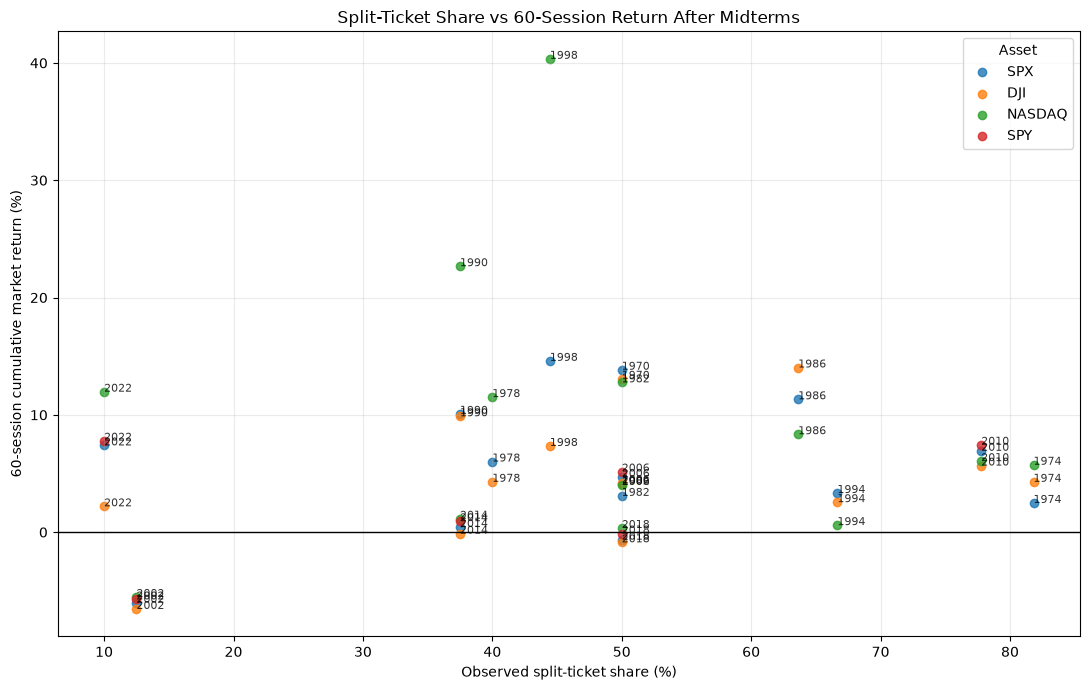

In [47]:

plot_data = market_political.dropna(
    subset=["split_ticket_share", "post60_return"]
).copy()

fig, ax = plt.subplots(figsize=(11, 7))

for asset in ASSETS:
    sub = plot_data[plot_data["asset"] == asset]
    if sub.empty:
        continue

    ax.scatter(
        sub["split_ticket_share"] * 100,
        sub["post60_return"],
        label=asset,
        alpha=0.8
    )

    for _, row in sub.iterrows():
        ax.annotate(
            str(int(row["year"])),
            (
                row["split_ticket_share"] * 100,
                row["post60_return"]
            ),
            fontsize=8,
            alpha=0.8
        )

ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Observed split-ticket share (%)")
ax.set_ylabel("60-session cumulative market return (%)")
ax.set_title(
    "Split-Ticket Share vs 60-Session Return After Midterms"
)
ax.grid(alpha=0.25)
ax.legend(title="Asset")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "split_ticket_share_vs_post60_return.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


In [50]:

comparison_rows = []

for asset in ASSETS:
    for h in HORIZONS:
        col = f"post{h}_return"
        sub = market_political[
            (market_political["asset"] == asset)
            & market_political["high_split_ticket"].notna()
        ].copy()

        high = sub.loc[sub["high_split_ticket"], col].dropna()
        other = sub.loc[~sub["high_split_ticket"], col].dropna()

        if len(high) >= 2 and len(other) >= 2:
            p_value = __import__("scipy").stats.ttest_ind(
                high, other, equal_var=False
            ).pvalue
        else:
            p_value = np.nan

        comparison_rows.append({
            "asset": asset,
            "horizon_sessions": h,
            "high_mismatch_n": len(high),
            "other_years_n": len(other),
            "high_mismatch_mean_pct": high.mean() if len(high) else np.nan,
            "other_years_mean_pct": other.mean() if len(other) else np.nan,
            "mean_difference_pp": (
                high.mean() - other.mean()
                if len(high) and len(other) else np.nan
            ),
            "high_mismatch_positive_rate": (
                (high > 0).mean() if len(high) else np.nan
            ),
            "other_years_positive_rate": (
                (other > 0).mean() if len(other) else np.nan
            ),
            "welch_ttest_p": p_value,
        })

political_market_tests = pd.DataFrame(comparison_rows)
display(political_market_tests.round(4))

political_market_tests.to_csv(
    OUTPUT_DIR / "high_vs_lower_split_ticket_market_tests.csv",
    index=False
)


KeyError: "None of [Index([-1, -2, -1, -1, -2, -1, -2, -1, -1, -1, -2, -1, -1, -1], dtype='object')] are in the [index]"

In [53]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

# ============================================================
# 1. OUTPUT LOCATION
# ============================================================

OUTPUT_DIR = Path("data/processed/midterm_final_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "midterm_election_market_research.xlsx"

# ============================================================
# 2. LOAD THE EXISTING EVENT PANEL
# ============================================================

if "event_panel" not in globals():
    raise NameError(
        "Run the cell that creates event_panel before exporting."
    )

df = event_panel.copy()

required = {"year", "asset"}
missing = required - set(df.columns)

if missing:
    raise ValueError(f"Missing columns in event_panel: {missing}")

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)
df["asset"] = df["asset"].astype(str).str.upper()

# QQQ excluded.
df = df[df["asset"].isin(["SPX", "DJI", "NASDAQ", "SPY"])].copy()

horizons = [
    "pre20_return",
    "post5_return",
    "post10_return",
    "post20_return",
    "post60_return",
]
horizons = [c for c in horizons if c in df.columns]

if not horizons:
    raise ValueError(
        "Expected return columns not found. Check event_panel.columns."
    )

# Values are already in percentage points:
# 2.5 means a 2.5% return. Do not multiply by 100.

# ============================================================
# 3. YEAR-WISE TABLE: ONE ROW PER ELECTION YEAR
# ============================================================

wide = df.pivot_table(
    index="year",
    columns="asset",
    values=horizons,
    aggfunc="first"
)

wide.columns = [
    f"{asset}_{horizon.replace('_return', '')}_pct"
    for horizon, asset in wide.columns
]

year_wise = wide.reset_index().sort_values("year")

asset_order = ["SPX", "DJI", "NASDAQ", "SPY"]
horizon_order = ["pre20", "post5", "post10", "post20", "post60"]

ordered_columns = ["year"]

for asset in asset_order:
    for horizon in horizon_order:
        col = f"{asset}_{horizon}_pct"
        if col in year_wise.columns:
            ordered_columns.append(col)

other_columns = [
    c for c in year_wise.columns if c not in ordered_columns
]
year_wise = year_wise[ordered_columns + other_columns]

# Add the SPX 60-session direction where available.
spx_col = "SPX_post60_pct"

if spx_col in year_wise.columns:
    year_wise["SPX_post60_direction"] = np.select(
        [
            year_wise[spx_col] > 0,
            year_wise[spx_col] < 0,
            year_wise[spx_col] == 0,
        ],
        ["Positive", "Negative", "Flat"],
        default="Unavailable",
    )

# ============================================================
# 4. LONG-FORM RETURNS TABLE
# ============================================================

returns_long = (
    df[["year", "asset"] + horizons]
    .sort_values(["year", "asset"])
    .reset_index(drop=True)
)

# ============================================================
# 5. SUMMARY STATISTICS BY ASSET AND HORIZON
# ============================================================

summary_rows = []

for asset in asset_order:
    asset_df = df[df["asset"] == asset]

    for horizon in horizons:
        values = pd.to_numeric(
            asset_df[horizon], errors="coerce"
        ).dropna()

        n = len(values)
        if n == 0:
            continue

        positive = int((values > 0).sum())
        negative = int((values < 0).sum())
        flat = int((values == 0).sum())

        ci_low, ci_high = proportion_confint(
            positive, n, alpha=0.05, method="wilson"
        )

        t_stat, t_pvalue = np.nan, np.nan
        if n >= 2 and values.std(ddof=1) > 0:
            result = stats.ttest_1samp(values, popmean=0)
            t_stat, t_pvalue = result.statistic, result.pvalue

        sign_pvalue = np.nan
        non_ties = positive + negative
        if non_ties > 0:
            sign_pvalue = stats.binomtest(
                positive,
                n=non_ties,
                p=0.5,
                alternative="two-sided",
            ).pvalue

        summary_rows.append({
            "asset": asset,
            "horizon": horizon,
            "n": n,
            "mean_return_pct": values.mean(),
            "median_return_pct": values.median(),
            "std_return_pct": values.std(ddof=1),
            "positive_count": positive,
            "negative_count": negative,
            "flat_count": flat,
            "positive_rate_pct": positive / n * 100,
            "negative_rate_pct": negative / n * 100,
            "positive_rate_95CI_low_pct": ci_low * 100,
            "positive_rate_95CI_high_pct": ci_high * 100,
            "t_statistic": t_stat,
            "t_test_pvalue": t_pvalue,
            "sign_test_pvalue": sign_pvalue,
        })

return_summary = pd.DataFrame(summary_rows)

# ============================================================
# 6. ALL NEGATIVE RETURN WINDOWS
# ============================================================

negative_rows = []

for horizon in horizons:
    temp = df.loc[
        pd.to_numeric(df[horizon], errors="coerce") < 0,
        ["year", "asset", horizon],
    ].copy()

    temp = temp.rename(columns={horizon: "return_pct"})
    temp["horizon"] = horizon
    negative_rows.append(temp)

negative_returns = (
    pd.concat(negative_rows, ignore_index=True)
    if negative_rows
    else pd.DataFrame(columns=["year", "asset", "return_pct", "horizon"])
)

negative_returns = negative_returns.sort_values(
    ["year", "asset", "horizon"]
)

# ============================================================
# 7. OPTIONAL EXISTING RESULTS
# ============================================================

def find_dataframe(names):
    for name in names:
        value = globals().get(name)
        if isinstance(value, pd.DataFrame):
            return value.copy()
    return None

uncertainty_tests = find_dataframe([
    "probability_table",
    "display_probability",
    "test_results",
    "statistical_tests",
])

political_flags = find_dataframe([
    "market_returns_with_political_flags",
    "political_market_panel",
    "political_years",
])

# ============================================================
# 8. EXPLANATION SHEET
# ============================================================

read_me = pd.DataFrame({
    "Item": [
        "Purpose",
        "Year_Wise",
        "Returns_Long",
        "Return units",
        "pre20_return",
        "post5_return",
        "post10_return",
        "post20_return",
        "post60_return",
        "Positive-return rate",
        "Confidence interval",
        "t-test p-value",
        "Sign-test p-value",
        "Political flags",
        "Missing values",
        "Causality",
        "Excluded asset",
    ],
    "Explanation": [
        "Historical descriptive analysis of US midterm elections and markets.",
        "One row per election year, with columns for each asset and return horizon.",
        "One row per election year and asset.",
        "Percentage points: 2.5 means +2.5%, not 250%.",
        "Return over the pre-election 20-session window as defined in the notebook.",
        "Cumulative price return over the first 5 subsequent trading sessions.",
        "Cumulative price return over the first 10 subsequent trading sessions.",
        "Cumulative price return over the first 20 subsequent trading sessions.",
        "Cumulative price return over the first 60 subsequent trading sessions.",
        "Observed share of windows with a return greater than zero.",
        "Wilson interval for the positive-return frequency.",
        "Tests whether the mean return differs from zero.",
        "Tests whether positive and negative outcomes are equally frequent; flat observations are excluded.",
        "Coverage may be limited to the states present in the political dataset.",
        "Blank values indicate unavailable observations, not zero returns.",
        "Historical association does not establish that elections caused market returns.",
        "QQQ is excluded.",
    ],
})

# ============================================================
# 9. EXPORT: NO COLOURS OR FORMATTING
# ============================================================

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    year_wise.to_excel(writer, sheet_name="Year_Wise", index=False)
    returns_long.to_excel(writer, sheet_name="Returns_Long", index=False)
    return_summary.to_excel(writer, sheet_name="Return_Summary", index=False)
    negative_returns.to_excel(writer, sheet_name="Negative_Returns", index=False)
    read_me.to_excel(writer, sheet_name="Read_Me", index=False)

    if uncertainty_tests is not None:
        uncertainty_tests.to_excel(
            writer, sheet_name="Uncertainty_Tests", index=False
        )

    if political_flags is not None:
        political_flags.to_excel(
            writer, sheet_name="Political_Flags", index=False
        )

print(f"Workbook saved to: {output_file.resolve()}")
print(f"Election years: {year_wise['year'].nunique()}")
print(f"Assets included: {sorted(df['asset'].unique())}")


Workbook saved to: C:\projects\research\mid_terms_effects\data\processed\midterm_final_outputs\midterm_election_market_research.xlsx
Election years: 16
Assets included: ['DJI', 'NASDAQ', 'SPX', 'SPY']
